# STEP 19 — Handwritten Bangla Dolil Preprocessing

This notebook evaluates the handwritten Bangla deed image dataset
before OCR.

Initial goals:

1. Verify the raw image dataset
2. Select representative samples
3. Inspect orientation and visual quality
4. Test minimal preprocessing
5. Evaluate OCR readiness

Raw images will remain unchanged.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path(
    r"D:\BhumiGuard-BD"
)

HANDWRITTEN_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "handwritten_dolil"
)

print(
    "Folder exists:",
    HANDWRITTEN_DIR.exists()
)

print(
    "Folder:",
    HANDWRITTEN_DIR
)

Folder exists: True
Folder: D:\BhumiGuard-BD\data\raw\handwritten_dolil


In [2]:
image_paths = sorted(
    HANDWRITTEN_DIR.glob(
        "*.jpg"
    )
)

print(
    "JPG images:",
    len(image_paths)
)

JPG images: 653


In [3]:
from PIL import Image
import pandas as pd


image_metadata = []

for image_path in image_paths:

    with Image.open(
        image_path
    ) as image:

        width, height = (
            image.size
        )

        image_metadata.append({
            "file_name":
                image_path.name,

            "path":
                image_path,

            "width":
                width,

            "height":
                height,

            "aspect_ratio":
                width / height,

            "pixel_area":
                width * height,
        })


image_meta_df = pd.DataFrame(
    image_metadata
)

image_meta_df.head()

,file_name,path,width,height,aspect_ratio,pixel_area
0,dolil_1.jpg,D:\BhumiGuard-BD\data\raw\handwritten_dolil\do...,1768,2768,0.638728,4893824
1,dolil_10.jpg,D:\BhumiGuard-BD\data\raw\handwritten_dolil\do...,1892,3008,0.628989,5691136
2,dolil_100.jpg,D:\BhumiGuard-BD\data\raw\handwritten_dolil\do...,4000,3000,1.333333,12000000
3,dolil_101.jpg,D:\BhumiGuard-BD\data\raw\handwritten_dolil\do...,4000,3000,1.333333,12000000
4,dolil_102.jpg,D:\BhumiGuard-BD\data\raw\handwritten_dolil\do...,4000,3000,1.333333,12000000


In [4]:
def geometry_category(
    width,
    height
):

    if width > height:
        return "LANDSCAPE_GEOMETRY"

    elif height > width:
        return "PORTRAIT_GEOMETRY"

    else:
        return "SQUARE_GEOMETRY"

In [5]:
image_meta_df[
    "geometry"
] = image_meta_df.apply(
    lambda row:
        geometry_category(
            row["width"],
            row["height"]
        ),
    axis=1
)

image_meta_df[
    "geometry"
].value_counts()

geometry
LANDSCAPE_GEOMETRY    492
PORTRAIT_GEOMETRY     161
Name: count, dtype: int64

In [6]:
print(
    "Images:",
    len(image_meta_df)
)

print(
    "Unique sizes:",
    image_meta_df[
        ["width", "height"]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Minimum width:",
    image_meta_df["width"].min()
)

print(
    "Maximum width:",
    image_meta_df["width"].max()
)

print(
    "Minimum height:",
    image_meta_df["height"].min()
)

print(
    "Maximum height:",
    image_meta_df["height"].max()
)

Images: 653
Unique sizes: 54
Minimum width: 720
Maximum width: 4608
Minimum height: 1280
Maximum height: 4608


In [7]:
selected_indices = set()

In [8]:
selected_indices.add(
    image_meta_df[
        "pixel_area"
    ].idxmin()
)

In [9]:
selected_indices.add(
    image_meta_df[
        "pixel_area"
    ].idxmax()
)

In [10]:
selected_indices.add(
    image_meta_df[
        "aspect_ratio"
    ].idxmin()
)

In [11]:
selected_indices.add(
    image_meta_df[
        "aspect_ratio"
    ].idxmax()
)

In [12]:
median_area = (
    image_meta_df[
        "pixel_area"
    ].median()
)

median_candidates = (
    image_meta_df.assign(
        distance_from_median=
            (
                image_meta_df[
                    "pixel_area"
                ]
                - median_area
            ).abs()
    )
    .sort_values(
        "distance_from_median"
    )
)

for idx in median_candidates.index:

    selected_indices.add(
        idx
    )

    if len(
        selected_indices
    ) >= 10:
        break

In [13]:
sample_df = (
    image_meta_df
    .loc[
        sorted(
            selected_indices
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

sample_df[
    [
        "file_name",
        "width",
        "height",
        "aspect_ratio",
        "geometry"
    ]
]

,file_name,width,height,aspect_ratio,geometry
0,dolil_127.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
1,dolil_138.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
2,dolil_139.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
3,dolil_140.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
4,dolil_30.jpg,1080,2400,0.450000,PORTRAIT_GEOMETRY
5,dolil_313.jpg,720,1280,0.562500,PORTRAIT_GEOMETRY
6,dolil_32.jpg,3448,2176,1.584559,LANDSCAPE_GEOMETRY
7,dolil_325.jpg,4608,3456,1.333333,LANDSCAPE_GEOMETRY
8,dolil_71.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
9,dolil_82.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY


In [14]:
print(
    "Representative samples:",
    len(sample_df)
)

Representative samples: 10


In [15]:
sample_images = []

for image_path in (
    sample_df[
        "path"
    ]
):

    with Image.open(
        image_path
    ) as image:

        sample_images.append(
            image.convert(
                "RGB"
            ).copy()
        )


print(
    "Images loaded:",
    len(sample_images)
)

Images loaded: 10


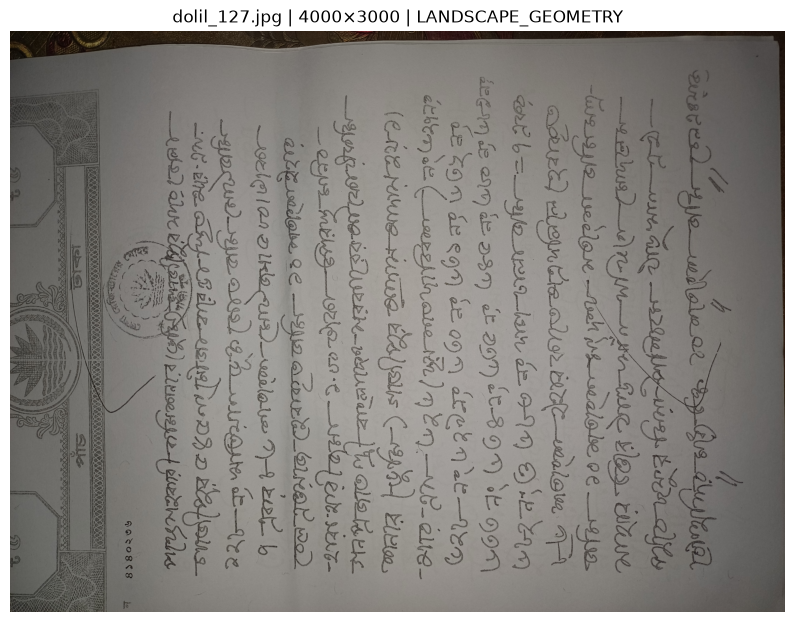

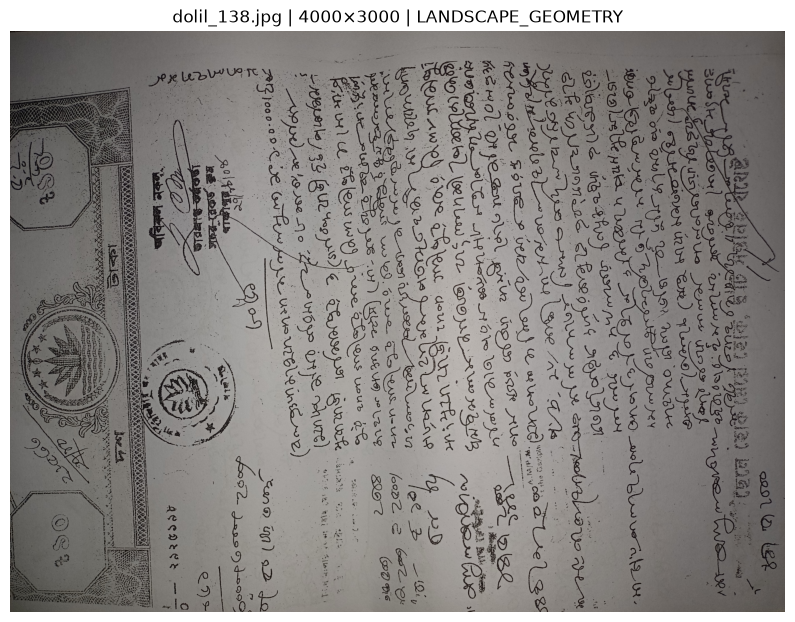

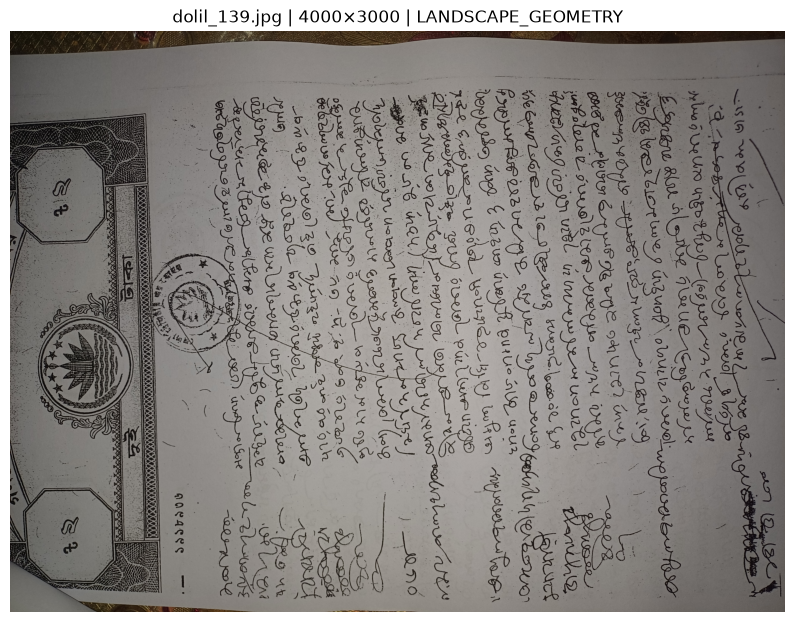

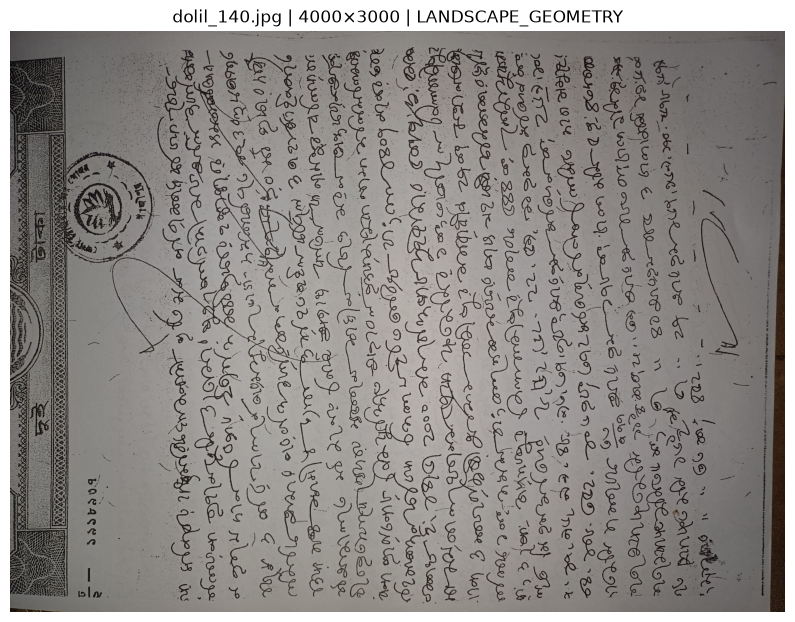

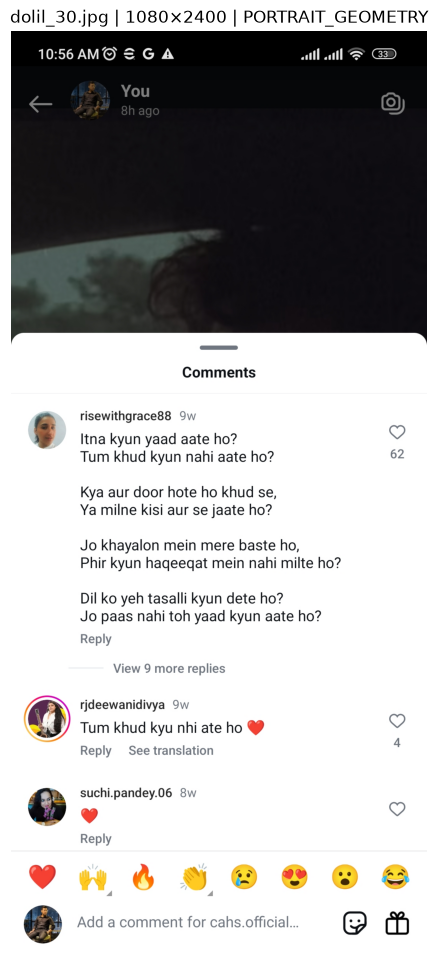

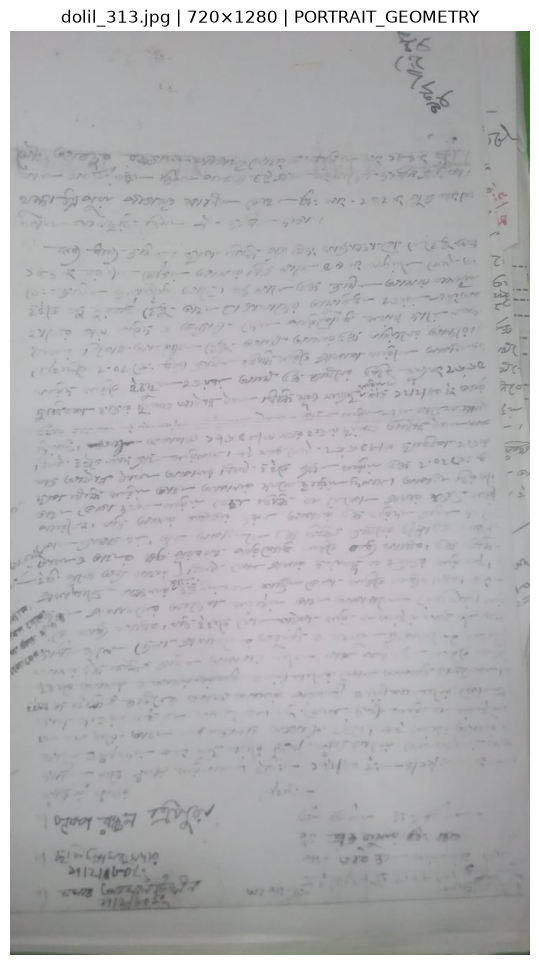

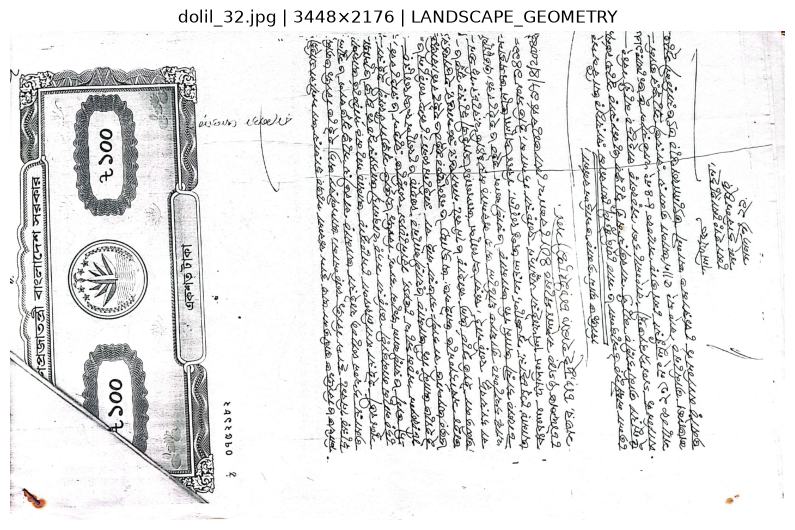

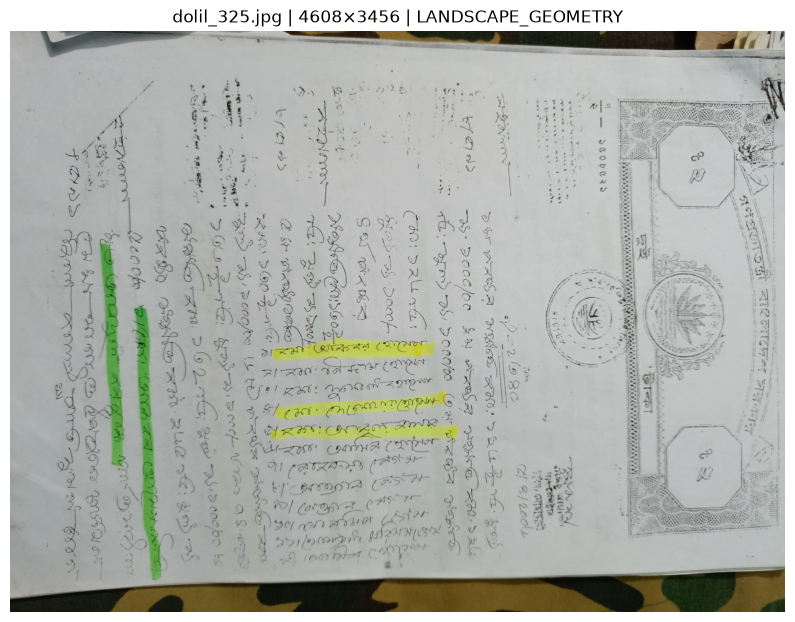

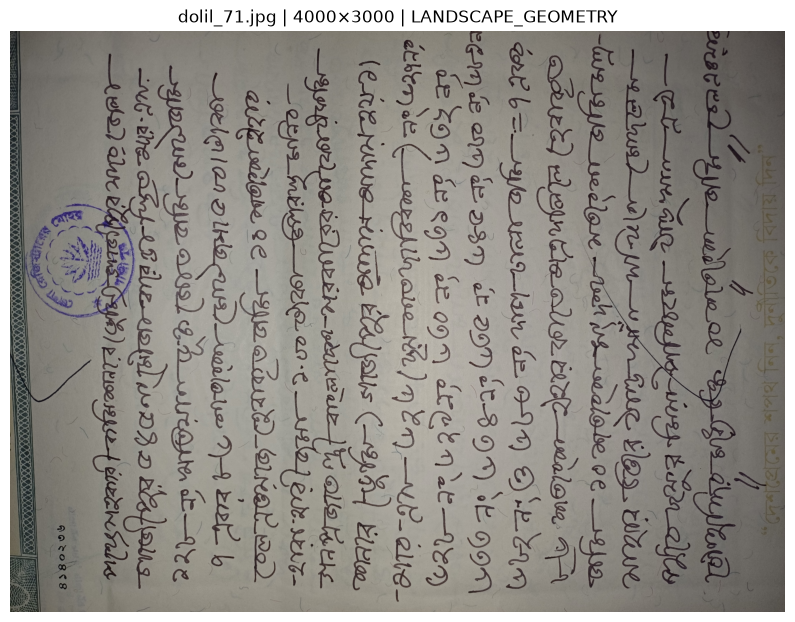

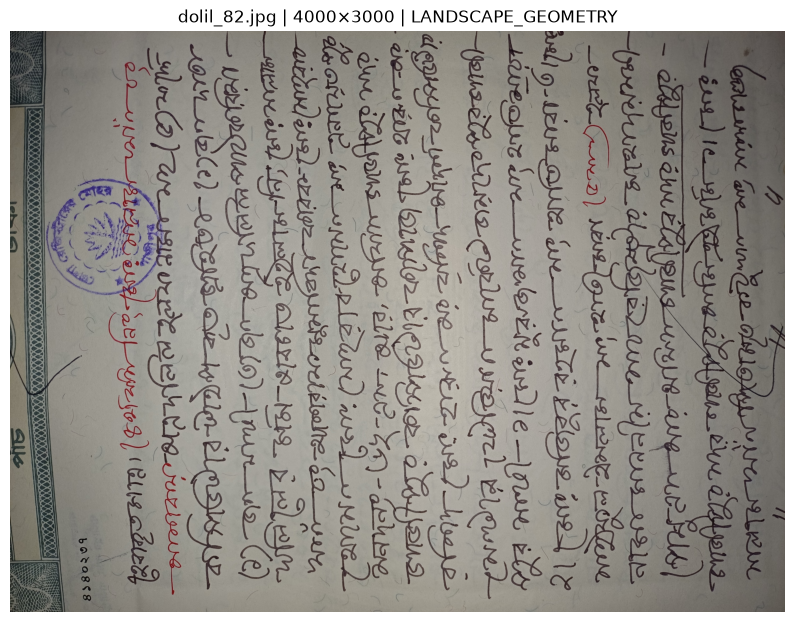

In [16]:
import matplotlib.pyplot as plt


for index, image in enumerate(
    sample_images
):

    row = sample_df.iloc[
        index
    ]

    plt.figure(
        figsize=(10, 12)
    )

    plt.imshow(
        image
    )

    plt.axis(
        "off"
    )

    plt.title(
        f"{row['file_name']} | "
        f"{row['width']}×{row['height']} | "
        f"{row['geometry']}"
    )

    plt.show()

In [17]:
sample_geometry_counts = (
    sample_df[
        "geometry"
    ].value_counts()
)

print(
    sample_geometry_counts
)

geometry
LANDSCAPE_GEOMETRY    8
PORTRAIT_GEOMETRY     2
Name: count, dtype: int64


In [18]:
print("STEP 19A SUMMARY")
print("----------------")

print(
    "Dataset images:",
    len(image_meta_df)
)

print(
    "Representative samples:",
    len(sample_df)
)

print(
    "Unique image sizes:",
    image_meta_df[
        ["width", "height"]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Portrait geometry:",
    (
        image_meta_df[
            "geometry"
        ]
        ==
        "PORTRAIT_GEOMETRY"
    ).sum()
)

print(
    "Landscape geometry:",
    (
        image_meta_df[
            "geometry"
        ]
        ==
        "LANDSCAPE_GEOMETRY"
    ).sum()
)

print(
    "\nRepresentative Sample Selection: READY"
)

STEP 19A SUMMARY
----------------
Dataset images: 653
Representative samples: 10
Unique image sizes: 54
Portrait geometry: 161
Landscape geometry: 492

Representative Sample Selection: READY


In [19]:
sample_df[
    [
        "file_name",
        "width",
        "height",
        "aspect_ratio",
        "geometry"
    ]
]

,file_name,width,height,aspect_ratio,geometry
0,dolil_127.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
1,dolil_138.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
2,dolil_139.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
3,dolil_140.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
4,dolil_30.jpg,1080,2400,0.450000,PORTRAIT_GEOMETRY
5,dolil_313.jpg,720,1280,0.562500,PORTRAIT_GEOMETRY
6,dolil_32.jpg,3448,2176,1.584559,LANDSCAPE_GEOMETRY
7,dolil_325.jpg,4608,3456,1.333333,LANDSCAPE_GEOMETRY
8,dolil_71.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY
9,dolil_82.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY


# STEP 19B — Orientation Detection Benchmark

Evaluate automatic orientation detection against manually reviewed
representative handwritten deed images.

Important:

- Geometry alone is not treated as orientation.
- Raw images are never modified.
- Non-document outliers are excluded from the orientation benchmark.

In [20]:
manual_orientation_labels = {
    "dolil_127.jpg": "ROTATED",
    "dolil_138.jpg": "ROTATED",
    "dolil_139.jpg": "ROTATED",
    "dolil_140.jpg": "ROTATED",
    "dolil_30.jpg": "NON_DEED_OUTLIER",
    "dolil_313.jpg": "UPRIGHT",
    "dolil_32.jpg": "ROTATED",
    "dolil_325.jpg": "ROTATED",
    "dolil_71.jpg": "ROTATED",
    "dolil_82.jpg": "ROTATED",
}

In [21]:
orientation_sample_df = (
    sample_df.copy()
)

orientation_sample_df[
    "manual_label"
] = orientation_sample_df[
    "file_name"
].map(
    manual_orientation_labels
)

orientation_sample_df[
    [
        "file_name",
        "geometry",
        "manual_label"
    ]
]

,file_name,geometry,manual_label
0,dolil_127.jpg,LANDSCAPE_GEOMETRY,ROTATED
1,dolil_138.jpg,LANDSCAPE_GEOMETRY,ROTATED
2,dolil_139.jpg,LANDSCAPE_GEOMETRY,ROTATED
3,dolil_140.jpg,LANDSCAPE_GEOMETRY,ROTATED
4,dolil_30.jpg,PORTRAIT_GEOMETRY,NON_DEED_OUTLIER
5,dolil_313.jpg,PORTRAIT_GEOMETRY,UPRIGHT
6,dolil_32.jpg,LANDSCAPE_GEOMETRY,ROTATED
7,dolil_325.jpg,LANDSCAPE_GEOMETRY,ROTATED
8,dolil_71.jpg,LANDSCAPE_GEOMETRY,ROTATED
9,dolil_82.jpg,LANDSCAPE_GEOMETRY,ROTATED


In [22]:
orientation_sample_df[
    "manual_label"
].value_counts()

manual_label
ROTATED             8
NON_DEED_OUTLIER    1
UPRIGHT             1
Name: count, dtype: int64

In [23]:
from pathlib import Path

SYSTEM_TESSDATA = Path(
    r"C:\Program Files\Tesseract-OCR\tessdata"
)

SYSTEM_OSD_MODEL = (
    SYSTEM_TESSDATA
    / "osd.traineddata"
)

print(
    "System tessdata exists:",
    SYSTEM_TESSDATA.exists()
)

print(
    "OSD model exists:",
    SYSTEM_OSD_MODEL.exists()
)

System tessdata exists: True
OSD model exists: True


In [24]:
def prepare_osd_image(
    image,
    max_side=2000
):
    output = (
        image.convert("RGB")
        .copy()
    )

    output.thumbnail(
        (
            max_side,
            max_side
        )
    )

    return output

In [25]:
test_osd_image = (
    prepare_osd_image(
        sample_images[0]
    )
)

print(
    "Original:",
    sample_images[0].size
)

print(
    "OSD copy:",
    test_osd_image.size
)

Original: (4000, 3000)
OSD copy: (2000, 1500)


In [27]:
from pathlib import Path
import os
import pytesseract

TESSERACT_EXE = Path(
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

SYSTEM_TESSDATA = Path(
    r"C:\Program Files\Tesseract-OCR\tessdata"
)

CUSTOM_TESSDATA = Path(
    r"D:\BhumiGuard-BD\tessdata"
)

print(
    "Tesseract executable:",
    TESSERACT_EXE.exists()
)

print(
    "System tessdata:",
    SYSTEM_TESSDATA.exists()
)

print(
    "OSD model:",
    (
        SYSTEM_TESSDATA
        / "osd.traineddata"
    ).exists()
)

Tesseract executable: True
System tessdata: True
OSD model: True


In [28]:
pytesseract.pytesseract.tesseract_cmd = str(
    TESSERACT_EXE
)

print(
    "Configured Tesseract:"
)

print(
    pytesseract.pytesseract.tesseract_cmd
)

print(
    "Version:",
    pytesseract.get_tesseract_version()
)

Configured Tesseract:
C:\Program Files\Tesseract-OCR\tesseract.exe
Version: 5.5.3.20260724


In [29]:
from pytesseract import Output

os.environ[
    "TESSDATA_PREFIX"
] = str(
    SYSTEM_TESSDATA
)

test_osd_image = prepare_osd_image(
    sample_images[0]
)

osd_test = (
    pytesseract.image_to_osd(
        test_osd_image,
        output_type=Output.DICT
    )
)

osd_test

{'page_num': 0,
 'orientation': 270,
 'rotate': 90,
 'orientation_conf': 1.47,
 'script': 'Arabic',
 'script_conf': 0.48}

In [30]:
os.environ[
    "TESSDATA_PREFIX"
] = str(
    CUSTOM_TESSDATA
)

print(
    "Restored tessdata:",
    os.environ[
        "TESSDATA_PREFIX"
    ]
)

Restored tessdata: D:\BhumiGuard-BD\tessdata


In [32]:
from pytesseract import (
    Output,
    TesseractError
)

pytesseract.pytesseract.tesseract_cmd = str(
    TESSERACT_EXE
)

original_tessdata_prefix = (
    os.environ.get(
        "TESSDATA_PREFIX"
    )
)

osd_results = []

os.environ[
    "TESSDATA_PREFIX"
] = str(
    SYSTEM_TESSDATA
)

try:

    for row, image in zip(
        orientation_sample_df.itertuples(),
        sample_images
    ):

        manual_label = (
            row.manual_label
        )

        if (
            manual_label
            == "NON_DEED_OUTLIER"
        ):
            continue

        osd_image = (
            prepare_osd_image(
                image
            )
        )

        try:

            result = (
                pytesseract
                .image_to_osd(
                    osd_image,
                    output_type=Output.DICT
                )
            )

            osd_results.append({
                "file_name":
                    row.file_name,

                "manual_label":
                    manual_label,

                "status":
                    "OK",

                "orientation":
                    result.get(
                        "orientation"
                    ),

                "rotate":
                    result.get(
                        "rotate"
                    ),

                "orientation_conf":
                    result.get(
                        "orientation_conf"
                    ),

                "script":
                    result.get(
                        "script"
                    ),

                "script_conf":
                    result.get(
                        "script_conf"
                    ),
            })

        except TesseractError:

            osd_results.append({
                "file_name":
                    row.file_name,

                "manual_label":
                    manual_label,

                "status":
                    "FAILED",

                "orientation":
                    None,

                "rotate":
                    None,

                "orientation_conf":
                    None,

                "script":
                    None,

                "script_conf":
                    None,
            })

finally:

    if (
        original_tessdata_prefix
        is None
    ):

        os.environ.pop(
            "TESSDATA_PREFIX",
            None
        )

    else:

        os.environ[
            "TESSDATA_PREFIX"
        ] = (
            original_tessdata_prefix
        )


print(
    "OSD processing complete."
)

OSD processing complete.


In [33]:
osd_results_df = pd.DataFrame(
    osd_results
)

osd_results_df

,file_name,manual_label,status,orientation,rotate,orientation_conf,script,script_conf
0,dolil_127.jpg,ROTATED,OK,270,90,1.47,Arabic,0.48
1,dolil_138.jpg,ROTATED,OK,90,270,0.16,Arabic,5.44
2,dolil_139.jpg,ROTATED,OK,90,270,2.82,Arabic,8.75
3,dolil_140.jpg,ROTATED,OK,90,270,1.95,Arabic,4.04
4,dolil_313.jpg,UPRIGHT,OK,180,180,0.70,Arabic,0.28
5,dolil_32.jpg,ROTATED,OK,180,180,2.35,Bengali,0.86
6,dolil_325.jpg,ROTATED,OK,180,180,0.10,Japanese,0.51
7,dolil_71.jpg,ROTATED,OK,270,90,1.03,Arabic,7.33
8,dolil_82.jpg,ROTATED,OK,270,90,0.94,Bengali,10.00


# STEP 19C — Four-Angle OCR Orientation Scoring

Tesseract OSD successfully processed the representative deed images,
but orientation confidence was low and script classification was
unreliable.

Therefore, final orientation is not selected directly from OSD.

This step evaluates each deed image at:

- 0 degrees
- 90 degrees
- 180 degrees
- 270 degrees

The orientation producing the strongest Bengali OCR evidence is selected
as the candidate corrected orientation.

Raw images remain unchanged.

In [34]:
import os
import pytesseract

pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

CUSTOM_TESSDATA = (
    r"D:\BhumiGuard-BD\tessdata"
)

os.environ[
    "TESSDATA_PREFIX"
] = CUSTOM_TESSDATA

print(
    "Bengali available:",
    "ben"
    in pytesseract.get_languages(
        config=""
    )
)

Bengali available: True


In [35]:
def rotate_candidate(
    image,
    angle
):
    if angle == 0:
        return image.copy()

    return image.rotate(
        angle,
        expand=True
    )

In [36]:
def prepare_orientation_image(
    image,
    max_side=1800
):
    output = (
        image
        .convert("RGB")
        .copy()
    )

    output.thumbnail(
        (
            max_side,
            max_side
        )
    )

    return output

In [37]:
def count_bengali_chars(
    text
):
    return sum(
        1
        for char in text
        if "\u0980"
        <= char
        <= "\u09FF"
    )

In [38]:
from pytesseract import Output
import pandas as pd


def get_ocr_metrics(
    image
):

    data = (
        pytesseract.image_to_data(
            image,
            lang="ben",
            config="--psm 6",
            output_type=Output.DATAFRAME
        )
    )

    valid = data[
        (
            data["conf"] >= 0
        )
        &
        (
            data["text"]
            .fillna("")
            .str.strip()
            != ""
        )
    ].copy()

    if len(valid) == 0:

        return {
            "mean_conf":
                0.0,

            "median_conf":
                0.0,

            "token_count":
                0,

            "text":
                "",

            "bengali_chars":
                0,
        }

    text = " ".join(
        valid[
            "text"
        ]
        .astype(str)
        .tolist()
    )

    return {
        "mean_conf":
            float(
                valid[
                    "conf"
                ].mean()
            ),

        "median_conf":
            float(
                valid[
                    "conf"
                ].median()
            ),

        "token_count":
            len(valid),

        "text":
            text,

        "bengali_chars":
            count_bengali_chars(
                text
            ),
    }

In [39]:
test_image = (
    prepare_orientation_image(
        sample_images[0]
    )
)

single_rotation_results = []

for angle in [
    0,
    90,
    180,
    270
]:

    candidate = (
        rotate_candidate(
            test_image,
            angle
        )
    )

    metrics = (
        get_ocr_metrics(
            candidate
        )
    )

    single_rotation_results.append({
        "angle":
            angle,

        "mean_conf":
            metrics[
                "mean_conf"
            ],

        "median_conf":
            metrics[
                "median_conf"
            ],

        "tokens":
            metrics[
                "token_count"
            ],

        "bengali_chars":
            metrics[
                "bengali_chars"
            ],
    })


single_rotation_df = pd.DataFrame(
    single_rotation_results
)

single_rotation_df

,angle,mean_conf,median_conf,tokens,bengali_chars
0,0,27.957360,28.366661,105,147
1,90,30.888668,24.133213,86,227
2,180,30.464887,29.826442,94,138
3,270,26.834494,22.180908,93,291


In [40]:
def calculate_orientation_score(
    bengali_chars,
    mean_conf,
    token_count
):

    return (
        bengali_chars
        *
        max(
            mean_conf,
            0
        )
        *
        max(
            token_count,
            1
        ) ** 0.5
    )

In [41]:
single_rotation_df[
    "score"
] = (
    single_rotation_df.apply(
        lambda row:
            calculate_orientation_score(
                row[
                    "bengali_chars"
                ],
                row[
                    "mean_conf"
                ],
                row[
                    "tokens"
                ]
            ),
        axis=1
    )
)

single_rotation_df.sort_values(
    "score",
    ascending=False
)

,angle,mean_conf,median_conf,tokens,bengali_chars,score
3,270,26.834494,22.180908,93,291,75305.704511
1,90,30.888668,24.133213,86,227,65024.086503
0,0,27.957360,28.366661,105,147,42112.221176
2,180,30.464887,29.826442,94,138,40760.789049


In [42]:
rotation_angles = [
    0,
    90,
    180,
    270
]

rotation_results = []


for row, image in zip(
    orientation_sample_df.itertuples(),
    sample_images
):

    if (
        row.manual_label
        == "NON_DEED_OUTLIER"
    ):
        continue

    prepared = (
        prepare_orientation_image(
            image
        )
    )

    for angle in rotation_angles:

        candidate = (
            rotate_candidate(
                prepared,
                angle
            )
        )

        metrics = (
            get_ocr_metrics(
                candidate
            )
        )

        score = (
            calculate_orientation_score(
                metrics[
                    "bengali_chars"
                ],
                metrics[
                    "mean_conf"
                ],
                metrics[
                    "token_count"
                ]
            )
        )

        rotation_results.append({
            "file_name":
                row.file_name,

            "manual_label":
                row.manual_label,

            "angle":
                angle,

            "mean_conf":
                metrics[
                    "mean_conf"
                ],

            "tokens":
                metrics[
                    "token_count"
                ],

            "bengali_chars":
                metrics[
                    "bengali_chars"
                ],

            "score":
                score,
        })

In [43]:
rotation_results_df = (
    pd.DataFrame(
        rotation_results
    )
)

rotation_results_df.head(
    12
)

,file_name,manual_label,angle,mean_conf,tokens,bengali_chars,score
0,dolil_127.jpg,ROTATED,0,27.957360,105,147,42112.221176
1,dolil_127.jpg,ROTATED,90,30.888668,86,227,65024.086503
2,dolil_127.jpg,ROTATED,180,30.464887,94,138,40760.789049
3,dolil_127.jpg,ROTATED,270,26.834494,93,291,75305.704511
4,dolil_138.jpg,ROTATED,0,28.114836,153,229,79637.341899
5,dolil_138.jpg,ROTATED,90,26.018549,148,389,123129.900272
6,dolil_138.jpg,ROTATED,180,31.390236,89,108,31982.568546
7,dolil_138.jpg,ROTATED,270,25.852762,160,357,116744.156388
8,dolil_139.jpg,ROTATED,0,30.981696,54,70,15936.762550
9,dolil_139.jpg,ROTATED,90,26.210122,128,297,88070.503363


In [44]:
print(
    "Rotation tests:",
    len(
        rotation_results_df
    )
)

Rotation tests: 36


In [45]:
best_rotation_df = (
    rotation_results_df
    .sort_values(
        [
            "file_name",
            "score"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "file_name"
    )
    .head(1)
    .reset_index(
        drop=True
    )
)

best_rotation_df[
    [
        "file_name",
        "manual_label",
        "angle",
        "mean_conf",
        "tokens",
        "bengali_chars",
        "score"
    ]
]

,file_name,manual_label,angle,mean_conf,tokens,bengali_chars,score
0,dolil_127.jpg,ROTATED,270,26.834494,93,291,75305.704511
1,dolil_138.jpg,ROTATED,90,26.018549,148,389,123129.900272
2,dolil_139.jpg,ROTATED,270,28.128197,135,303,99026.494355
3,dolil_140.jpg,ROTATED,270,27.966434,159,411,144936.404015
4,dolil_313.jpg,UPRIGHT,0,24.832203,296,682,291370.431262
5,dolil_32.jpg,ROTATED,270,30.845615,127,362,125835.700176
6,dolil_325.jpg,ROTATED,90,30.642905,238,460,217458.425527
7,dolil_71.jpg,ROTATED,270,23.410511,70,246,48183.131424
8,dolil_82.jpg,ROTATED,270,23.055143,38,132,18760.030640


In [46]:
orientation_decisions = []

for file_name, group in (
    rotation_results_df
    .groupby(
        "file_name"
    )
):

    ranked = (
        group
        .sort_values(
            "score",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )

    best = ranked.iloc[0]
    second = ranked.iloc[1]

    if (
        best["score"]
        > 0
    ):

        margin = (
            best["score"]
            - second["score"]
        ) / best["score"]

    else:

        margin = 0.0

    orientation_decisions.append({
        "file_name":
            file_name,

        "best_angle":
            int(
                best["angle"]
            ),

        "best_score":
            best["score"],

        "second_score":
            second["score"],

        "score_margin":
            margin,

        "bengali_chars":
            int(
                best[
                    "bengali_chars"
                ]
            ),

        "mean_conf":
            best[
                "mean_conf"
            ],
    })


orientation_decision_df = (
    pd.DataFrame(
        orientation_decisions
    )
)

orientation_decision_df

,file_name,best_angle,best_score,second_score,score_margin,bengali_chars,mean_conf
0,dolil_127.jpg,270,75305.704511,65024.086503,0.136532,291,26.834494
1,dolil_138.jpg,90,123129.900272,116744.156388,0.051862,389,26.018549
2,dolil_139.jpg,270,99026.494355,88070.503363,0.110637,303,28.128197
3,dolil_140.jpg,270,144936.404015,111793.830410,0.228670,411,27.966434
4,dolil_313.jpg,0,291370.431262,266530.779926,0.085251,682,24.832203
5,dolil_32.jpg,270,125835.700176,58806.609856,0.532671,362,30.845615
6,dolil_325.jpg,90,217458.425527,173018.017075,0.204363,460,30.642905
7,dolil_71.jpg,270,48183.131424,44794.675641,0.070325,246,23.410511
8,dolil_82.jpg,270,18760.030640,17565.710400,0.063663,132,23.055143


In [47]:
def orientation_decision_status(
    margin
):

    if margin <= 0:
        return "AMBIGUOUS"

    return "CANDIDATE"

In [48]:
orientation_decision_df[
    "decision_status"
] = (
    orientation_decision_df[
        "score_margin"
    ].apply(
        orientation_decision_status
    )
)

orientation_decision_df

,file_name,best_angle,best_score,second_score,score_margin,bengali_chars,mean_conf,decision_status
0,dolil_127.jpg,270,75305.704511,65024.086503,0.136532,291,26.834494,CANDIDATE
1,dolil_138.jpg,90,123129.900272,116744.156388,0.051862,389,26.018549,CANDIDATE
2,dolil_139.jpg,270,99026.494355,88070.503363,0.110637,303,28.128197,CANDIDATE
3,dolil_140.jpg,270,144936.404015,111793.830410,0.228670,411,27.966434,CANDIDATE
4,dolil_313.jpg,0,291370.431262,266530.779926,0.085251,682,24.832203,CANDIDATE
5,dolil_32.jpg,270,125835.700176,58806.609856,0.532671,362,30.845615,CANDIDATE
6,dolil_325.jpg,90,217458.425527,173018.017075,0.204363,460,30.642905,CANDIDATE
7,dolil_71.jpg,270,48183.131424,44794.675641,0.070325,246,23.410511,CANDIDATE
8,dolil_82.jpg,270,18760.030640,17565.710400,0.063663,132,23.055143,CANDIDATE


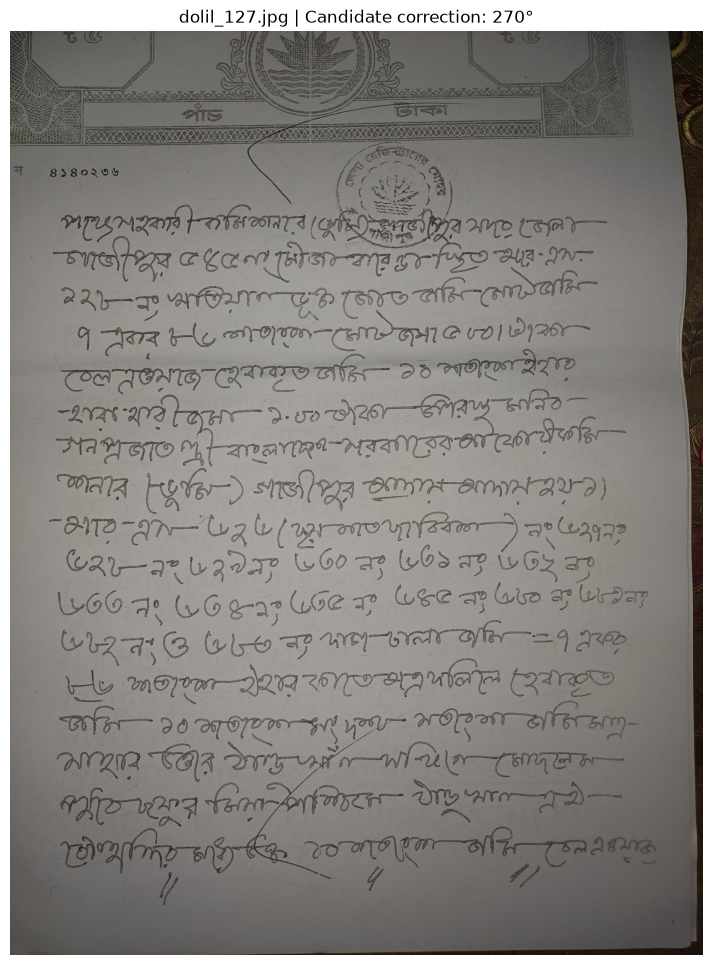

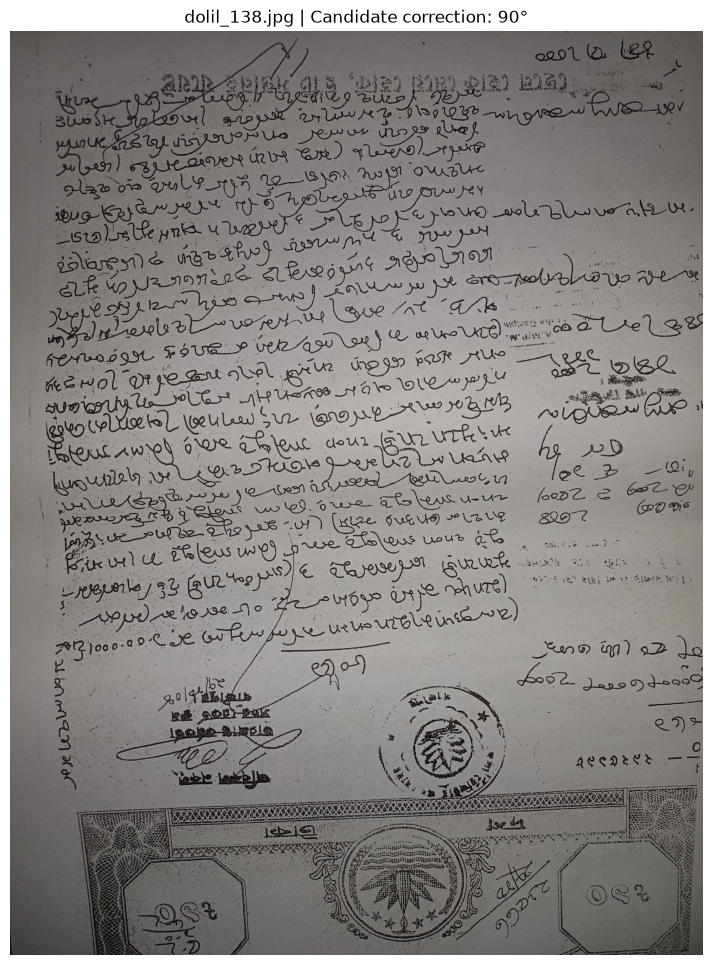

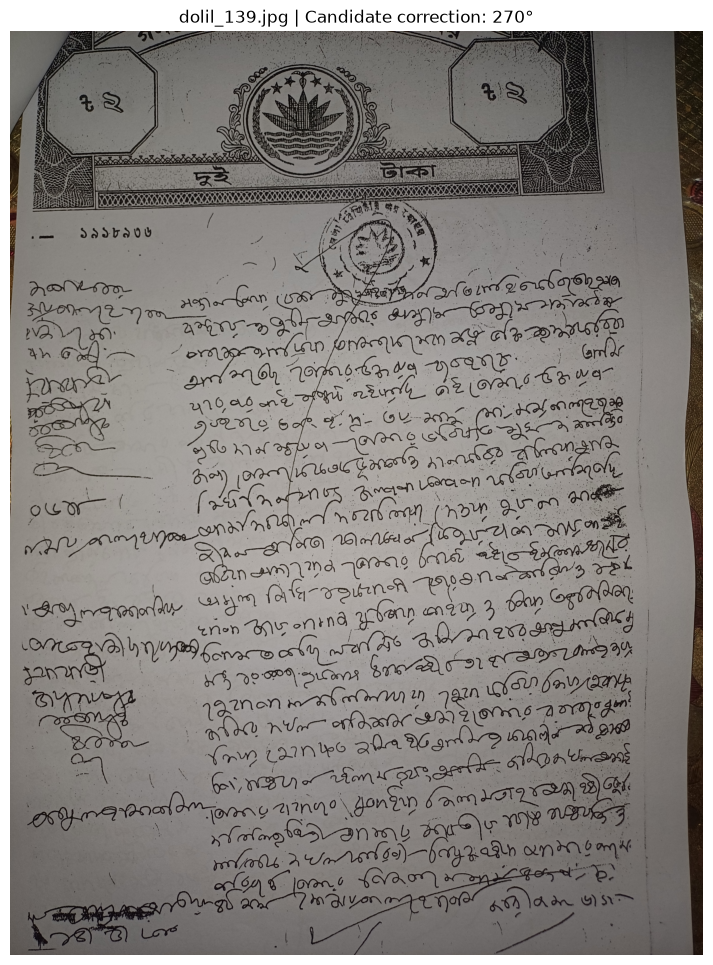

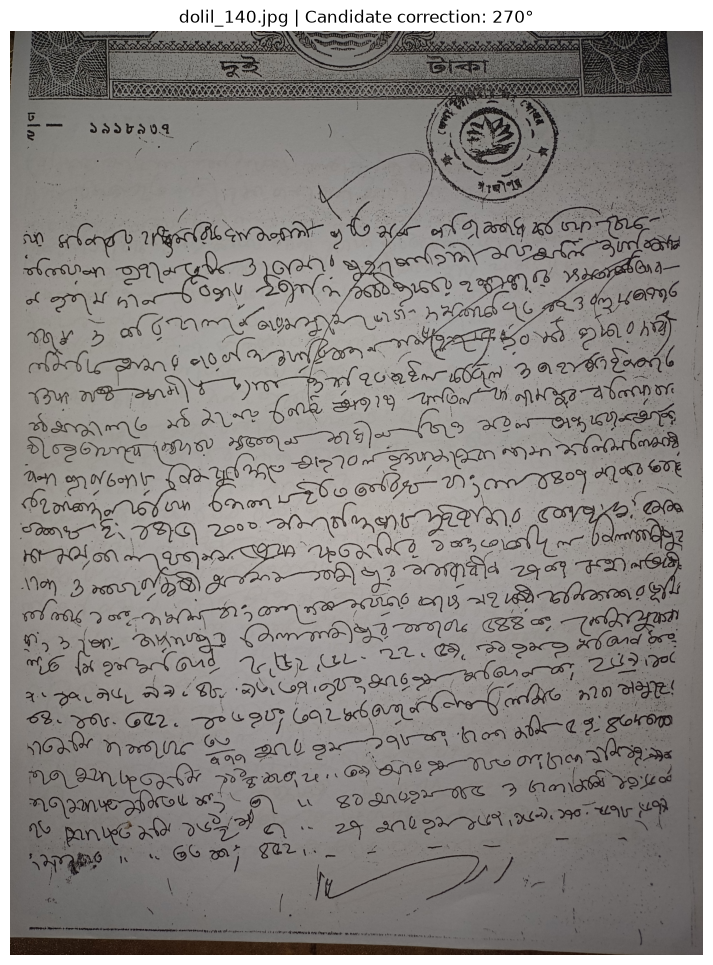

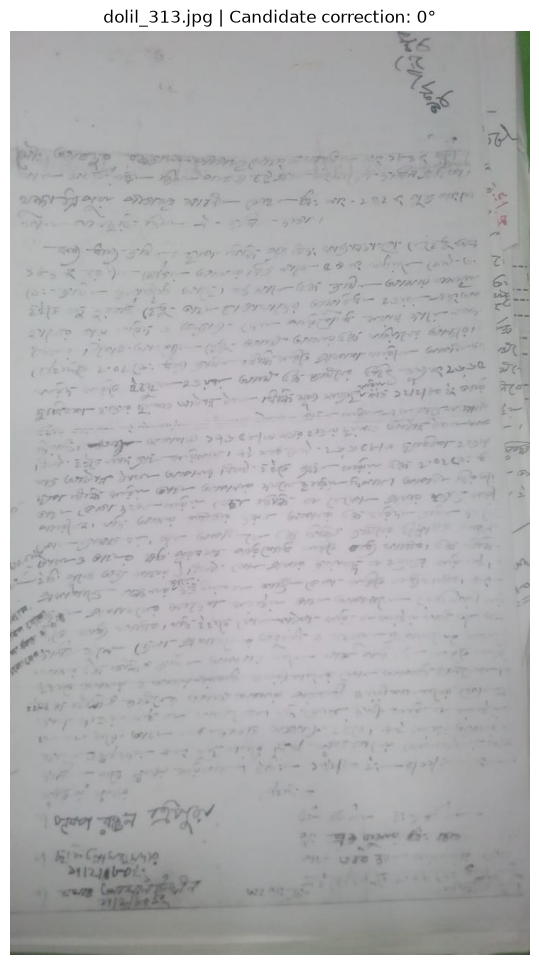

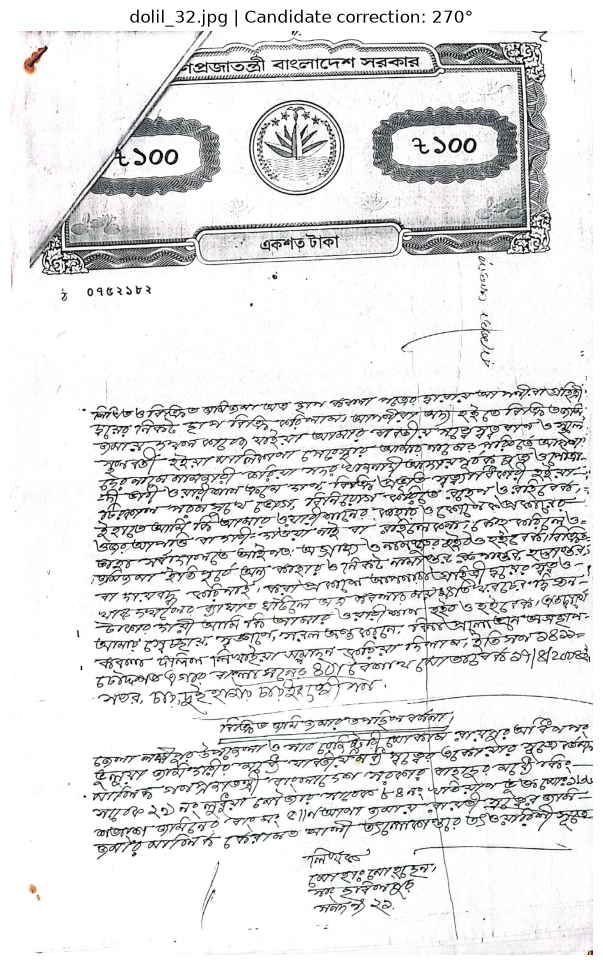

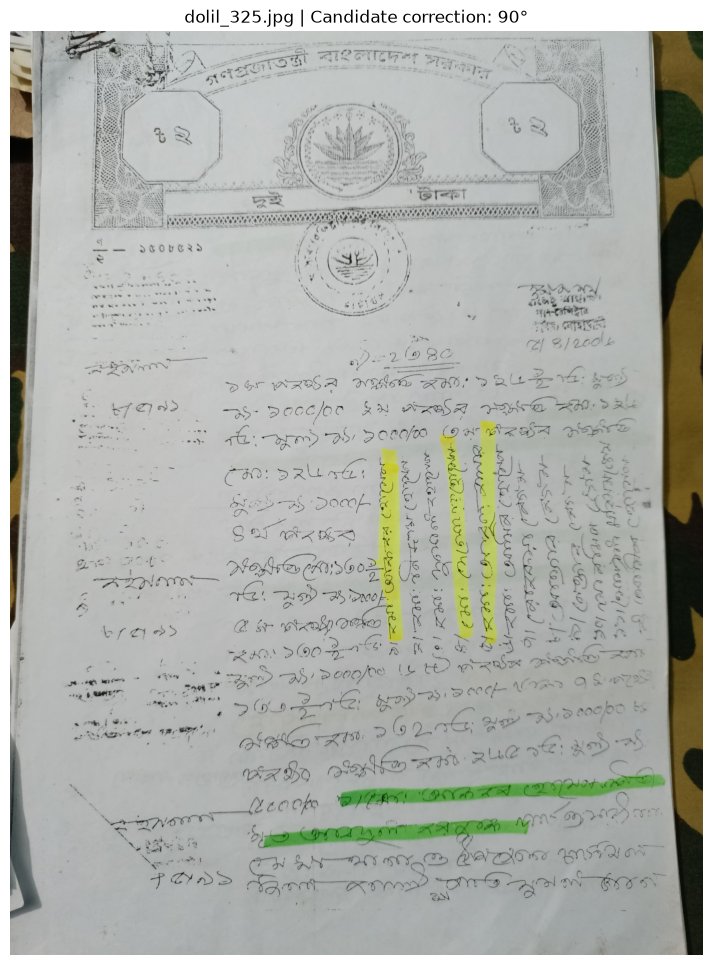

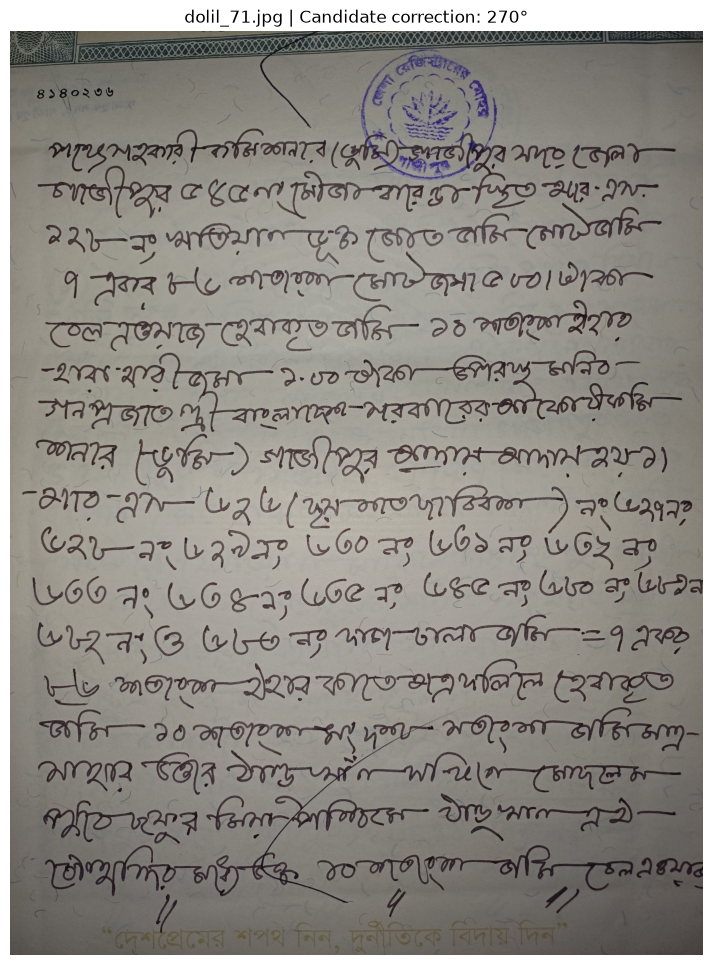

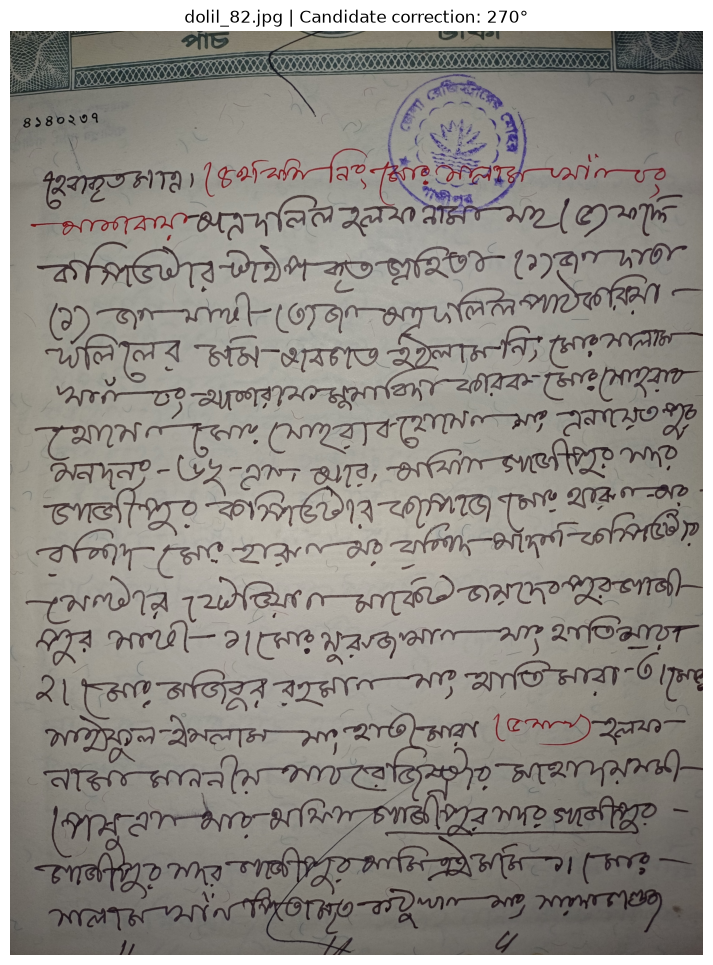

In [49]:
for row in (
    orientation_decision_df
    .itertuples()
):

    sample_index = (
        orientation_sample_df[
            orientation_sample_df[
                "file_name"
            ]
            == row.file_name
        ]
        .index[0]
    )

    original = (
        sample_images[
            sample_index
        ]
    )

    corrected = (
        rotate_candidate(
            original,
            row.best_angle
        )
    )

    plt.figure(
        figsize=(10, 12)
    )

    plt.imshow(
        corrected
    )

    plt.axis(
        "off"
    )

    plt.title(
        f"{row.file_name} | "
        f"Candidate correction: "
        f"{row.best_angle}°"
    )

    plt.show()

In [50]:
print("STEP 19C SUMMARY")
print("----------------")

print(
    "Deed-like samples:",
    len(
        orientation_decision_df
    )
)

print(
    "Rotation candidates per image:",
    4
)

print(
    "Total OCR rotation tests:",
    len(
        rotation_results_df
    )
)

print(
    "Candidate orientations:",
    (
        orientation_decision_df[
            "decision_status"
        ]
        == "CANDIDATE"
    ).sum()
)

print(
    "Ambiguous orientations:",
    (
        orientation_decision_df[
            "decision_status"
        ]
        == "AMBIGUOUS"
    ).sum()
)

print(
    "\nFour-Angle Orientation Benchmark: TESTED"
)

STEP 19C SUMMARY
----------------
Deed-like samples: 9
Rotation candidates per image: 4
Total OCR rotation tests: 36
Candidate orientations: 9
Ambiguous orientations: 0

Four-Angle Orientation Benchmark: TESTED


In [51]:
orientation_decision_df[
    [
        "file_name",
        "best_angle",
        "score_margin",
        "bengali_chars",
        "mean_conf"
    ]
]

,file_name,best_angle,score_margin,bengali_chars,mean_conf
0,dolil_127.jpg,270,0.136532,291,26.834494
1,dolil_138.jpg,90,0.051862,389,26.018549
2,dolil_139.jpg,270,0.110637,303,28.128197
3,dolil_140.jpg,270,0.228670,411,27.966434
4,dolil_313.jpg,0,0.085251,682,24.832203
5,dolil_32.jpg,270,0.532671,362,30.845615
6,dolil_325.jpg,90,0.204363,460,30.642905
7,dolil_71.jpg,270,0.070325,246,23.410511
8,dolil_82.jpg,270,0.063663,132,23.055143


In [52]:
visual_orientation_check = {
    "dolil_127.jpg": True,
    "dolil_138.jpg": False,
    "dolil_139.jpg": True,
    "dolil_140.jpg": True,
    "dolil_313.jpg": True,
    "dolil_32.jpg": True,
    "dolil_325.jpg": True,
    "dolil_71.jpg": True,
    "dolil_82.jpg": True,
}

In [53]:
orientation_decision_df[
    "visually_correct"
] = (
    orientation_decision_df[
        "file_name"
    ].map(
        visual_orientation_check
    )
)

orientation_decision_df[
    [
        "file_name",
        "best_angle",
        "score_margin",
        "visually_correct"
    ]
]

,file_name,best_angle,score_margin,visually_correct
0,dolil_127.jpg,270,0.136532,True
1,dolil_138.jpg,90,0.051862,False
2,dolil_139.jpg,270,0.110637,True
3,dolil_140.jpg,270,0.228670,True
4,dolil_313.jpg,0,0.085251,True
5,dolil_32.jpg,270,0.532671,True
6,dolil_325.jpg,90,0.204363,True
7,dolil_71.jpg,270,0.070325,True
8,dolil_82.jpg,270,0.063663,True


In [54]:
visual_accuracy = (
    orientation_decision_df[
        "visually_correct"
    ].mean()
)

print(
    "Visual orientation accuracy:",
    round(
        visual_accuracy,
        3
    )
)

Visual orientation accuracy: 0.889


In [55]:
ORIENTATION_AUTO_THRESHOLD = 0.10


def assign_orientation_action(
    margin
):
    if margin >= ORIENTATION_AUTO_THRESHOLD:
        return "AUTO_CORRECT"

    return "REVIEW"

In [56]:
orientation_decision_df[
    "orientation_action"
] = (
    orientation_decision_df[
        "score_margin"
    ].apply(
        assign_orientation_action
    )
)

orientation_decision_df[
    [
        "file_name",
        "best_angle",
        "score_margin",
        "visually_correct",
        "orientation_action"
    ]
]

,file_name,best_angle,score_margin,visually_correct,orientation_action
0,dolil_127.jpg,270,0.136532,True,AUTO_CORRECT
1,dolil_138.jpg,90,0.051862,False,REVIEW
2,dolil_139.jpg,270,0.110637,True,AUTO_CORRECT
3,dolil_140.jpg,270,0.228670,True,AUTO_CORRECT
4,dolil_313.jpg,0,0.085251,True,REVIEW
5,dolil_32.jpg,270,0.532671,True,AUTO_CORRECT
6,dolil_325.jpg,90,0.204363,True,AUTO_CORRECT
7,dolil_71.jpg,270,0.070325,True,REVIEW
8,dolil_82.jpg,270,0.063663,True,REVIEW


In [57]:
auto_orientation_df = (
    orientation_decision_df[
        orientation_decision_df[
            "orientation_action"
        ] == "AUTO_CORRECT"
    ]
)

review_orientation_df = (
    orientation_decision_df[
        orientation_decision_df[
            "orientation_action"
        ] == "REVIEW"
    ]
)

In [58]:
print(
    "Auto-correct cases:",
    len(auto_orientation_df)
)

print(
    "Review cases:",
    len(review_orientation_df)
)

print(
    "Auto-correct visually correct:",
    int(
        auto_orientation_df[
            "visually_correct"
        ].sum()
    )
)

Auto-correct cases: 5
Review cases: 4
Auto-correct visually correct: 5


In [59]:
if len(auto_orientation_df) > 0:

    auto_precision = (
        auto_orientation_df[
            "visually_correct"
        ].mean()
    )

else:

    auto_precision = None


print(
    "Auto-correct precision:",
    round(
        auto_precision,
        3
    )
    if auto_precision is not None
    else None
)

Auto-correct precision: 1.0


In [60]:
review_orientation_df[
    [
        "file_name",
        "best_angle",
        "score_margin",
        "visually_correct"
    ]
]

,file_name,best_angle,score_margin,visually_correct
1,dolil_138.jpg,90,0.051862,False
4,dolil_313.jpg,0,0.085251,True
7,dolil_71.jpg,270,0.070325,True
8,dolil_82.jpg,270,0.063663,True


In [61]:
orientation_policy = {
    "primary_method":
        "FOUR_ANGLE_BENGALI_OCR",

    "auto_threshold":
        ORIENTATION_AUTO_THRESHOLD,

    "high_confidence_action":
        "AUTO_CORRECT",

    "low_confidence_action":
        "REVIEW",

    "osd_role":
        "SECONDARY_ONLY",

    "geometry_role":
        "WEAK_CLUE_ONLY",

    "raw_images_modified":
        False,
}

orientation_policy

{'primary_method': 'FOUR_ANGLE_BENGALI_OCR',
 'auto_threshold': 0.1,
 'high_confidence_action': 'AUTO_CORRECT',
 'low_confidence_action': 'REVIEW',
 'osd_role': 'SECONDARY_ONLY',
 'geometry_role': 'WEAK_CLUE_ONLY',
 'raw_images_modified': False}

In [62]:
auto_count = len(
    auto_orientation_df
)

review_count = len(
    review_orientation_df
)

known_failures_auto = int(
    (
        auto_orientation_df[
            "visually_correct"
        ] == False
    ).sum()
)


print("STEP 19D SUMMARY")
print("----------------")

print(
    "Benchmark deed images:",
    len(
        orientation_decision_df
    )
)

print(
    "Auto threshold:",
    ORIENTATION_AUTO_THRESHOLD
)

print(
    "Auto-correct cases:",
    auto_count
)

print(
    "Review cases:",
    review_count
)

print(
    "Auto-correct errors:",
    known_failures_auto
)

print(
    "Auto-correct precision:",
    round(
        auto_precision,
        3
    )
    if auto_precision is not None
    else None
)

print(
    "Known failed case captured by review:",
    (
        "dolil_138.jpg"
        in review_orientation_df[
            "file_name"
        ].values
    )
)

print(
    "\nHybrid Orientation Policy: READY"
)

STEP 19D SUMMARY
----------------
Benchmark deed images: 9
Auto threshold: 0.1
Auto-correct cases: 5
Review cases: 4
Auto-correct errors: 0
Auto-correct precision: 1.0
Known failed case captured by review: True

Hybrid Orientation Policy: READY


# STEP 19E — Content and Image-Quality QC Baseline

Evaluate representative images for:

- deed-like vs non-deed content
- brightness
- contrast
- possible blur
- edge/detail strength
- image entropy

Thresholds will not be guessed.

The representative sample will first be used to understand the
metric distributions before defining any automatic QC rules.

In [63]:
manual_content_labels = {
    "dolil_127.jpg": "DEED_LIKE",
    "dolil_138.jpg": "DEED_LIKE",
    "dolil_139.jpg": "DEED_LIKE",
    "dolil_140.jpg": "DEED_LIKE",

    "dolil_30.jpg": "NON_DEED_OUTLIER",

    "dolil_313.jpg": "DEED_LIKE",
    "dolil_32.jpg": "DEED_LIKE",
    "dolil_325.jpg": "DEED_LIKE",
    "dolil_71.jpg": "DEED_LIKE",
    "dolil_82.jpg": "DEED_LIKE",
}

In [64]:
manual_quality_notes = {
    "dolil_30.jpg":
        "NON_DEED_SCREENSHOT",

    "dolil_313.jpg":
        "FAINT_LOW_CONTRAST",
}

In [65]:
import numpy as np
from PIL import ImageOps, ImageFilter

In [66]:
def calculate_quality_metrics(
    image
):

    gray = ImageOps.grayscale(
        image
    )

    array = np.asarray(
        gray,
        dtype=np.float32
    )

    mean_brightness = float(
        array.mean()
    )

    contrast_std = float(
        array.std()
    )

    dark_fraction = float(
        (
            array < 40
        ).mean()
    )

    bright_fraction = float(
        (
            array > 245
        ).mean()
    )

    edge_image = gray.filter(
        ImageFilter.FIND_EDGES
    )

    edge_array = np.asarray(
        edge_image,
        dtype=np.float32
    )

    edge_strength = float(
        edge_array.std()
    )

    hist = np.histogram(
        array,
        bins=256,
        range=(0, 256)
    )[0]

    probabilities = (
        hist
        / hist.sum()
    )

    probabilities = (
        probabilities[
            probabilities > 0
        ]
    )

    entropy = float(
        -np.sum(
            probabilities
            * np.log2(
                probabilities
            )
        )
    )

    return {
        "brightness":
            mean_brightness,

        "contrast":
            contrast_std,

        "dark_fraction":
            dark_fraction,

        "bright_fraction":
            bright_fraction,

        "edge_strength":
            edge_strength,

        "entropy":
            entropy,
    }

In [67]:
quality_results = []

for row, image in zip(
    sample_df.itertuples(),
    sample_images
):

    metrics = (
        calculate_quality_metrics(
            image
        )
    )

    quality_results.append({
        "file_name":
            row.file_name,

        "content_label":
            manual_content_labels[
                row.file_name
            ],

        "manual_note":
            manual_quality_notes.get(
                row.file_name,
                "NONE"
            ),

        **metrics
    })


quality_metrics_df = pd.DataFrame(
    quality_results
)

quality_metrics_df

,file_name,content_label,manual_note,brightness,contrast,dark_fraction,bright_fraction,edge_strength,entropy
0,dolil_127.jpg,DEED_LIKE,NONE,123.588821,30.902020,0.020934,0.000000,23.391457,6.775995
1,dolil_138.jpg,DEED_LIKE,NONE,125.030998,39.263943,0.070454,0.000000,34.434292,6.978776
2,dolil_139.jpg,DEED_LIKE,NONE,123.556801,41.362728,0.092310,0.000000,33.865925,6.923636
3,dolil_140.jpg,DEED_LIKE,NONE,128.942184,40.259766,0.079713,0.000000,34.088093,6.874998
4,dolil_30.jpg,NON_DEED_OUTLIER,NON_DEED_SCREENSHOT,170.455856,111.685837,0.300828,0.617067,36.952202,3.007795
5,dolil_313.jpg,DEED_LIKE,FAINT_LOW_CONTRAST,171.680817,16.574469,0.000000,0.000000,14.856104,5.888109
6,dolil_32.jpg,DEED_LIKE,NONE,225.222916,70.366600,0.075109,0.757682,62.883240,3.933827
7,dolil_325.jpg,DEED_LIKE,NONE,169.482834,38.678104,0.032511,0.000000,13.784565,6.248559
8,dolil_71.jpg,DEED_LIKE,NONE,131.114502,34.853714,0.021698,0.000000,22.911690,6.864130
9,dolil_82.jpg,DEED_LIKE,NONE,134.408630,36.614708,0.020585,0.000000,24.736662,6.895871


In [68]:
quality_metrics_df[
    [
        "file_name",
        "content_label",
        "manual_note",
        "brightness",
        "contrast",
        "edge_strength",
        "entropy"
    ]
]

,file_name,content_label,manual_note,brightness,contrast,edge_strength,entropy
0,dolil_127.jpg,DEED_LIKE,NONE,123.588821,30.902020,23.391457,6.775995
1,dolil_138.jpg,DEED_LIKE,NONE,125.030998,39.263943,34.434292,6.978776
2,dolil_139.jpg,DEED_LIKE,NONE,123.556801,41.362728,33.865925,6.923636
3,dolil_140.jpg,DEED_LIKE,NONE,128.942184,40.259766,34.088093,6.874998
4,dolil_30.jpg,NON_DEED_OUTLIER,NON_DEED_SCREENSHOT,170.455856,111.685837,36.952202,3.007795
5,dolil_313.jpg,DEED_LIKE,FAINT_LOW_CONTRAST,171.680817,16.574469,14.856104,5.888109
6,dolil_32.jpg,DEED_LIKE,NONE,225.222916,70.366600,62.883240,3.933827
7,dolil_325.jpg,DEED_LIKE,NONE,169.482834,38.678104,13.784565,6.248559
8,dolil_71.jpg,DEED_LIKE,NONE,131.114502,34.853714,22.911690,6.864130
9,dolil_82.jpg,DEED_LIKE,NONE,134.408630,36.614708,24.736662,6.895871


In [69]:
quality_metrics_df[
    [
        "file_name",
        "contrast",
        "brightness",
        "manual_note"
    ]
].sort_values(
    "contrast"
)

,file_name,contrast,brightness,manual_note
5,dolil_313.jpg,16.574469,171.680817,FAINT_LOW_CONTRAST
0,dolil_127.jpg,30.902020,123.588821,NONE
8,dolil_71.jpg,34.853714,131.114502,NONE
9,dolil_82.jpg,36.614708,134.408630,NONE
7,dolil_325.jpg,38.678104,169.482834,NONE
1,dolil_138.jpg,39.263943,125.030998,NONE
3,dolil_140.jpg,40.259766,128.942184,NONE
2,dolil_139.jpg,41.362728,123.556801,NONE
6,dolil_32.jpg,70.366600,225.222916,NONE
4,dolil_30.jpg,111.685837,170.455856,NON_DEED_SCREENSHOT


In [70]:
quality_metrics_df[
    [
        "file_name",
        "edge_strength",
        "contrast",
        "manual_note"
    ]
].sort_values(
    "edge_strength"
)

,file_name,edge_strength,contrast,manual_note
7,dolil_325.jpg,13.784565,38.678104,NONE
5,dolil_313.jpg,14.856104,16.574469,FAINT_LOW_CONTRAST
8,dolil_71.jpg,22.911690,34.853714,NONE
0,dolil_127.jpg,23.391457,30.902020,NONE
9,dolil_82.jpg,24.736662,36.614708,NONE
2,dolil_139.jpg,33.865925,41.362728,NONE
3,dolil_140.jpg,34.088093,40.259766,NONE
1,dolil_138.jpg,34.434292,39.263943,NONE
4,dolil_30.jpg,36.952202,111.685837,NON_DEED_SCREENSHOT
6,dolil_32.jpg,62.883240,70.366600,NONE


In [71]:
quality_metrics_df[
    [
        "file_name",
        "dark_fraction",
        "bright_fraction",
        "brightness"
    ]
].sort_values(
    "bright_fraction",
    ascending=False
)

,file_name,dark_fraction,bright_fraction,brightness
6,dolil_32.jpg,0.075109,0.757682,225.222916
4,dolil_30.jpg,0.300828,0.617067,170.455856
1,dolil_138.jpg,0.070454,0.000000,125.030998
0,dolil_127.jpg,0.020934,0.000000,123.588821
3,dolil_140.jpg,0.079713,0.000000,128.942184
2,dolil_139.jpg,0.092310,0.000000,123.556801
5,dolil_313.jpg,0.000000,0.000000,171.680817
7,dolil_325.jpg,0.032511,0.000000,169.482834
8,dolil_71.jpg,0.021698,0.000000,131.114502
9,dolil_82.jpg,0.020585,0.000000,134.408630


In [72]:
quality_with_orientation_df = (
    quality_metrics_df
    .merge(
        orientation_decision_df[
            [
                "file_name",
                "best_angle",
                "score_margin",
                "visually_correct"
            ]
        ],
        on="file_name",
        how="left"
    )
)

quality_with_orientation_df

,file_name,content_label,manual_note,brightness,contrast,dark_fraction,bright_fraction,edge_strength,entropy,best_angle,score_margin,visually_correct
0,dolil_127.jpg,DEED_LIKE,NONE,123.588821,30.902020,0.020934,0.000000,23.391457,6.775995,270.0,0.136532,True
1,dolil_138.jpg,DEED_LIKE,NONE,125.030998,39.263943,0.070454,0.000000,34.434292,6.978776,90.0,0.051862,False
2,dolil_139.jpg,DEED_LIKE,NONE,123.556801,41.362728,0.092310,0.000000,33.865925,6.923636,270.0,0.110637,True
3,dolil_140.jpg,DEED_LIKE,NONE,128.942184,40.259766,0.079713,0.000000,34.088093,6.874998,270.0,0.228670,True
4,dolil_30.jpg,NON_DEED_OUTLIER,NON_DEED_SCREENSHOT,170.455856,111.685837,0.300828,0.617067,36.952202,3.007795,NaN,NaN,NaN
5,dolil_313.jpg,DEED_LIKE,FAINT_LOW_CONTRAST,171.680817,16.574469,0.000000,0.000000,14.856104,5.888109,0.0,0.085251,True
6,dolil_32.jpg,DEED_LIKE,NONE,225.222916,70.366600,0.075109,0.757682,62.883240,3.933827,270.0,0.532671,True
7,dolil_325.jpg,DEED_LIKE,NONE,169.482834,38.678104,0.032511,0.000000,13.784565,6.248559,90.0,0.204363,True
8,dolil_71.jpg,DEED_LIKE,NONE,131.114502,34.853714,0.021698,0.000000,22.911690,6.864130,270.0,0.070325,True
9,dolil_82.jpg,DEED_LIKE,NONE,134.408630,36.614708,0.020585,0.000000,24.736662,6.895871,270.0,0.063663,True


In [73]:
quality_metrics_df.groupby(
    "content_label"
)[
    [
        "brightness",
        "contrast",
        "edge_strength",
        "entropy"
    ]
].mean()

,brightness,contrast,edge_strength,entropy
content_label,,,,
DEED_LIKE,148.114278,38.764006,29.439114,6.375989
NON_DEED_OUTLIER,170.455856,111.685837,36.952202,3.007795


In [74]:
metric_columns = [
    "brightness",
    "contrast",
    "edge_strength",
    "entropy",
]

In [75]:
median_values = (
    quality_metrics_df[
        metric_columns
    ].median()
)

deviation_df = (
    quality_metrics_df[
        metric_columns
    ]
    .sub(
        median_values
    )
    .abs()
)

In [76]:
mad_values = (
    quality_metrics_df[
        metric_columns
    ]
    .sub(
        median_values
    )
    .abs()
    .median()
)

In [77]:
safe_mad = (
    mad_values.replace(
        0,
        1
    )
)

In [78]:
quality_metrics_df[
    "relative_outlier_score"
] = (
    deviation_df
    .div(
        safe_mad
    )
    .mean(
        axis=1
    )
)

In [79]:
quality_metrics_df[
    [
        "file_name",
        "content_label",
        "manual_note",
        "relative_outlier_score"
    ]
].sort_values(
    "relative_outlier_score",
    ascending=False
)

,file_name,content_label,manual_note,relative_outlier_score
4,dolil_30.jpg,NON_DEED_OUTLIER,NON_DEED_SCREENSHOT,14.189623
6,dolil_32.jpg,DEED_LIKE,NONE,11.794536
5,dolil_313.jpg,DEED_LIKE,FAINT_LOW_CONTRAST,5.143124
7,dolil_325.jpg,DEED_LIKE,NONE,2.741832
0,dolil_127.jpg,DEED_LIKE,NONE,1.193652
2,dolil_139.jpg,DEED_LIKE,NONE,0.817164
1,dolil_138.jpg,DEED_LIKE,NONE,0.744053
8,dolil_71.jpg,DEED_LIKE,NONE,0.704847
9,dolil_82.jpg,DEED_LIKE,NONE,0.555893
3,dolil_140.jpg,DEED_LIKE,NONE,0.502229


In [80]:
def initial_qc_status(
    file_name
):

    if (
        manual_content_labels[
            file_name
        ]
        == "NON_DEED_OUTLIER"
    ):
        return "REVIEW_NON_DEED"

    if (
        manual_quality_notes.get(
            file_name
        )
        ==
        "FAINT_LOW_CONTRAST"
    ):
        return "REVIEW_IMAGE_QUALITY"

    return "VISUAL_PASS"

In [81]:
quality_metrics_df[
    "initial_qc_status"
] = (
    quality_metrics_df[
        "file_name"
    ].apply(
        initial_qc_status
    )
)

quality_metrics_df[
    [
        "file_name",
        "initial_qc_status"
    ]
]

,file_name,initial_qc_status
0,dolil_127.jpg,VISUAL_PASS
1,dolil_138.jpg,VISUAL_PASS
2,dolil_139.jpg,VISUAL_PASS
3,dolil_140.jpg,VISUAL_PASS
4,dolil_30.jpg,REVIEW_NON_DEED
5,dolil_313.jpg,REVIEW_IMAGE_QUALITY
6,dolil_32.jpg,VISUAL_PASS
7,dolil_325.jpg,VISUAL_PASS
8,dolil_71.jpg,VISUAL_PASS
9,dolil_82.jpg,VISUAL_PASS


In [82]:
print("STEP 19E SUMMARY")
print("----------------")

print(
    "Representative images:",
    len(
        quality_metrics_df
    )
)

print(
    "Deed-like:",
    (
        quality_metrics_df[
            "content_label"
        ]
        == "DEED_LIKE"
    ).sum()
)

print(
    "Non-deed outliers:",
    (
        quality_metrics_df[
            "content_label"
        ]
        == "NON_DEED_OUTLIER"
    ).sum()
)

print(
    "Visual-pass images:",
    (
        quality_metrics_df[
            "initial_qc_status"
        ]
        == "VISUAL_PASS"
    ).sum()
)

print(
    "Image-quality review:",
    (
        quality_metrics_df[
            "initial_qc_status"
        ]
        ==
        "REVIEW_IMAGE_QUALITY"
    ).sum()
)

print(
    "Non-deed review:",
    (
        quality_metrics_df[
            "initial_qc_status"
        ]
        ==
        "REVIEW_NON_DEED"
    ).sum()
)

print(
    "\nImage Quality / Content QC Baseline: TESTED"
)

STEP 19E SUMMARY
----------------
Representative images: 10
Deed-like: 9
Non-deed outliers: 1
Visual-pass images: 8
Image-quality review: 1
Non-deed review: 1

Image Quality / Content QC Baseline: TESTED


In [83]:
quality_metrics_df[
    [
        "file_name",
        "brightness",
        "contrast",
        "edge_strength",
        "entropy",
        "relative_outlier_score",
        "initial_qc_status"
    ]
]

,file_name,brightness,contrast,edge_strength,entropy,relative_outlier_score,initial_qc_status
0,dolil_127.jpg,123.588821,30.902020,23.391457,6.775995,1.193652,VISUAL_PASS
1,dolil_138.jpg,125.030998,39.263943,34.434292,6.978776,0.744053,VISUAL_PASS
2,dolil_139.jpg,123.556801,41.362728,33.865925,6.923636,0.817164,VISUAL_PASS
3,dolil_140.jpg,128.942184,40.259766,34.088093,6.874998,0.502229,VISUAL_PASS
4,dolil_30.jpg,170.455856,111.685837,36.952202,3.007795,14.189623,REVIEW_NON_DEED
5,dolil_313.jpg,171.680817,16.574469,14.856104,5.888109,5.143124,REVIEW_IMAGE_QUALITY
6,dolil_32.jpg,225.222916,70.366600,62.883240,3.933827,11.794536,VISUAL_PASS
7,dolil_325.jpg,169.482834,38.678104,13.784565,6.248559,2.741832,VISUAL_PASS
8,dolil_71.jpg,131.114502,34.853714,22.911690,6.864130,0.704847,VISUAL_PASS
9,dolil_82.jpg,134.408630,36.614708,24.736662,6.895871,0.555893,VISUAL_PASS


# STEP 19F — Targeted Preprocessing Benefit Benchmark

Evaluate whether image preprocessing improves Bengali OCR quality.

Three representative deed cases are tested:

- faint / low-contrast document
- normal control document
- statistically unusual but valid document

Preprocessing is accepted only if OCR evidence improves.

Raw images remain unchanged.

In [84]:
preprocessing_test_files = [
    "dolil_313.jpg",
    "dolil_140.jpg",
    "dolil_32.jpg",
]

In [85]:
def get_sample_image(
    file_name
):

    index = (
        sample_df[
            sample_df[
                "file_name"
            ] == file_name
        ]
        .index[0]
    )

    return (
        sample_images[
            index
        ].copy()
    )

In [86]:
def get_best_angle(
    file_name
):

    row = (
        orientation_decision_df[
            orientation_decision_df[
                "file_name"
            ] == file_name
        ]
        .iloc[0]
    )

    return int(
        row[
            "best_angle"
        ]
    )

In [87]:
corrected_test_images = {}

for file_name in (
    preprocessing_test_files
):

    image = get_sample_image(
        file_name
    )

    angle = get_best_angle(
        file_name
    )

    corrected = (
        rotate_candidate(
            image,
            angle
        )
    )

    corrected_test_images[
        file_name
    ] = corrected

    print(
        file_name,
        "->",
        angle,
        "degrees"
    )

dolil_313.jpg -> 0 degrees
dolil_140.jpg -> 270 degrees
dolil_32.jpg -> 270 degrees


In [88]:
from PIL import (
    ImageOps,
    ImageEnhance,
    ImageFilter,
)

In [89]:
def create_preprocessing_variants(
    image
):

    gray = ImageOps.grayscale(
        image
    )

    autocontrast = (
        ImageOps.autocontrast(
            gray
        )
    )

    contrast_boost = (
        ImageEnhance.Contrast(
            gray
        )
        .enhance(
            1.5
        )
    )

    sharpened = (
        autocontrast.filter(
            ImageFilter.UnsharpMask(
                radius=1.5,
                percent=120,
                threshold=3
            )
        )
    )

    return {
        "RAW":
            image,

        "GRAY":
            gray,

        "AUTOCONTRAST":
            autocontrast,

        "CONTRAST_1_5":
            contrast_boost,

        "AUTOCONTRAST_SHARP":
            sharpened,
    }

In [90]:
def prepare_preprocessing_ocr(
    image,
    max_side=2000
):

    output = image.copy()

    output.thumbnail(
        (
            max_side,
            max_side
        )
    )

    return output

In [91]:
def preprocessing_ocr_metrics(
    image
):

    prepared = (
        prepare_preprocessing_ocr(
            image
        )
    )

    data = (
        pytesseract.image_to_data(
            prepared,
            lang="ben",
            config="--psm 6",
            output_type=Output.DATAFRAME
        )
    )

    valid = data[
        (
            data["conf"] >= 0
        )
        &
        (
            data["text"]
            .fillna("")
            .str.strip()
            != ""
        )
    ].copy()

    if len(valid) == 0:

        return {
            "tokens": 0,
            "mean_conf": 0.0,
            "bengali_chars": 0,
            "text": "",
        }

    text = " ".join(
        valid[
            "text"
        ]
        .astype(str)
        .tolist()
    )

    return {
        "tokens":
            len(valid),

        "mean_conf":
            float(
                valid[
                    "conf"
                ].mean()
            ),

        "bengali_chars":
            count_bengali_chars(
                text
            ),

        "text":
            text,
    }

In [92]:
def preprocessing_score(
    bengali_chars,
    mean_conf,
    tokens
):

    return (
        bengali_chars
        *
        max(
            mean_conf,
            0
        )
        *
        max(
            tokens,
            1
        ) ** 0.5
    )

In [93]:
preprocessing_results = []

preprocessing_texts = {}


for file_name, image in (
    corrected_test_images.items()
):

    variants = (
        create_preprocessing_variants(
            image
        )
    )

    for variant_name, variant in (
        variants.items()
    ):

        metrics = (
            preprocessing_ocr_metrics(
                variant
            )
        )

        score = (
            preprocessing_score(
                metrics[
                    "bengali_chars"
                ],
                metrics[
                    "mean_conf"
                ],
                metrics[
                    "tokens"
                ]
            )
        )

        key = (
            file_name,
            variant_name
        )

        preprocessing_texts[
            key
        ] = metrics[
            "text"
        ]

        preprocessing_results.append({
            "file_name":
                file_name,

            "variant":
                variant_name,

            "tokens":
                metrics[
                    "tokens"
                ],

            "mean_conf":
                metrics[
                    "mean_conf"
                ],

            "bengali_chars":
                metrics[
                    "bengali_chars"
                ],

            "score":
                score,
        })

In [94]:
preprocessing_results_df = (
    pd.DataFrame(
        preprocessing_results
    )
)

preprocessing_results_df

,file_name,variant,tokens,mean_conf,bengali_chars,score
0,dolil_313.jpg,RAW,296,24.832203,682,291370.431262
1,dolil_313.jpg,GRAY,220,23.839873,500,176801.233311
2,dolil_313.jpg,AUTOCONTRAST,264,27.213021,621,274580.902432
3,dolil_313.jpg,CONTRAST_1_5,225,22.305317,541,181007.650917
4,dolil_313.jpg,AUTOCONTRAST_SHARP,285,26.900843,654,297006.578053
5,dolil_140.jpg,RAW,155,28.623934,392,139695.120862
6,dolil_140.jpg,GRAY,135,28.311872,326,107239.076501
7,dolil_140.jpg,AUTOCONTRAST,156,28.052506,392,137347.267986
8,dolil_140.jpg,CONTRAST_1_5,124,24.752216,356,98123.929303
9,dolil_140.jpg,AUTOCONTRAST_SHARP,115,29.804024,278,88852.288020


In [95]:
print(
    "Preprocessing tests:",
    len(
        preprocessing_results_df
    )
)

Preprocessing tests: 15


In [96]:
best_preprocessing_df = (
    preprocessing_results_df
    .sort_values(
        [
            "file_name",
            "score"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "file_name"
    )
    .head(1)
    .reset_index(
        drop=True
    )
)

best_preprocessing_df

,file_name,variant,tokens,mean_conf,bengali_chars,score
0,dolil_140.jpg,RAW,155,28.623934,392,139695.120862
1,dolil_313.jpg,AUTOCONTRAST_SHARP,285,26.900843,654,297006.578053
2,dolil_32.jpg,RAW,125,25.998128,340,98827.089577


In [97]:
raw_scores_df = (
    preprocessing_results_df[
        preprocessing_results_df[
            "variant"
        ] == "RAW"
    ][
        [
            "file_name",
            "score"
        ]
    ]
    .rename(
        columns={
            "score":
                "raw_score"
        }
    )
)

In [98]:
preprocessing_comparison_df = (
    best_preprocessing_df
    .merge(
        raw_scores_df,
        on="file_name",
        how="left"
    )
)

In [99]:
preprocessing_comparison_df[
    "relative_improvement"
] = (
    (
        preprocessing_comparison_df[
            "score"
        ]
        -
        preprocessing_comparison_df[
            "raw_score"
        ]
    )
    /
    preprocessing_comparison_df[
        "raw_score"
    ].replace(
        0,
        np.nan
    )
)

preprocessing_comparison_df

,file_name,variant,tokens,mean_conf,bengali_chars,score,raw_score,relative_improvement
0,dolil_140.jpg,RAW,155,28.623934,392,139695.120862,139695.120862,0.000000
1,dolil_313.jpg,AUTOCONTRAST_SHARP,285,26.900843,654,297006.578053,291370.431262,0.019344
2,dolil_32.jpg,RAW,125,25.998128,340,98827.089577,98827.089577,0.000000


In [100]:
dolil313_results = (
    preprocessing_results_df[
        preprocessing_results_df[
            "file_name"
        ]
        == "dolil_313.jpg"
    ]
    .sort_values(
        "score",
        ascending=False
    )
)

dolil313_results

,file_name,variant,tokens,mean_conf,bengali_chars,score
4,dolil_313.jpg,AUTOCONTRAST_SHARP,285,26.900843,654,297006.578053
0,dolil_313.jpg,RAW,296,24.832203,682,291370.431262
2,dolil_313.jpg,AUTOCONTRAST,264,27.213021,621,274580.902432
3,dolil_313.jpg,CONTRAST_1_5,225,22.305317,541,181007.650917
1,dolil_313.jpg,GRAY,220,23.839873,500,176801.233311


In [101]:
top2_313 = (
    dolil313_results[
        "variant"
    ]
    .head(2)
    .tolist()
)

for variant in top2_313:

    print("\n")
    print("=" * 60)

    print(
        "dolil_313.jpg",
        variant
    )

    print("=" * 60)

    print(
        preprocessing_texts[
            (
                "dolil_313.jpg",
                variant
            )
        ][:1200]
    )



dolil_313.jpg AUTOCONTRAST_SHARP
॥ ও সীট, ৮ শির ষ্ঠ ১ বি. নি রিবা (৮ পল পপ) দিত 2০82৮৮72554 রর! ৯৮ ৮৮ এ 5 রর ১ রি চি ৯৮৮ জের আত গতর ভুত পারনি ডে ৮ শর ০ উনিভিরি ভাতা র্‌ ক -স)-এট 53 এ ু রি হেটে এ ভুলে লরি ৭০6৯5১৮ পেিিল: দি লজ 0. লতি কসররিত ৮472৯ এ এত ফেিজএ নি চি 65৮ভট ছি ৫০) অল 275 ০ 1 হঠাত ক এল হে লতি? 255 বেস ০তবুদুসগিজহগোশ উর 2 ৬ সা এ জুস ৬৯৯৮ শি লহ ঠলিিং টস, /+/৮-5৮7৮5-- শিকারি 17772 কসর ৮০০৪ (১ পতি সিল ৮৪৮-০প16 এ, ৮ ০224 এপস ই2% 2০৯ পা ৫ ভগ্ন ভি পা লে নি মি ঈপ্ে ১ ১১,২0১ দলটি লেন ৫ নানা১১ ৯৭৫৮15 এন্টি 2৮ লিক রিবন ঞ চার নট ১757-৮৯-৮৮ ভল্িিিকিা £ চা কেরা ১৮০৮ ০পঠপা (৭ - ৯ 58 পিল কট ভিত ুস স্পট লট রনি জেল দেকপ চি সপ ছিলটিগা7 জল ৯ ০2 হি. 5৮৮০০৮৮৮১০৮ নার হেড ৮৪৮৯১ ৪৮ 1৮ ভঠিকাগতি সিসি লন 2৪ পা নত অগা রেপ দল কল জে ১টি শিরক): 4 নন (পপ 27 ১৮ এমা শর লি: ১০27৩ ৪৮ ২ তল লি ৮ পপি ২/পনকত ২৯ লি 2 ৮০ 22 পচ টি পদ জহাপ্লী পর জাগি এমি ৮৫ পুনে € ৮ টি . ] রা 1) এগ ১৮০7 ০) 45 ৬৫ ১ » নক ্ ৭) / নিন ) ঈদ ক ০০ ক নিসা ০ স্স- * স্পা ৫১১০ রকি রর ৪ ইডি. খা পনি পাস ু/শশল ২০৮ ] 72৮ নিস” স্প্স্ -* ১7 পা পি 7777৮০

In [102]:
preprocessing_comparison_df[
    [
        "file_name",
        "variant",
        "raw_score",
        "score",
        "relative_improvement"
    ]
]

,file_name,variant,raw_score,score,relative_improvement
0,dolil_140.jpg,RAW,139695.120862,139695.120862,0.000000
1,dolil_313.jpg,AUTOCONTRAST_SHARP,291370.431262,297006.578053,0.019344
2,dolil_32.jpg,RAW,98827.089577,98827.089577,0.000000


In [103]:
print("STEP 19F SUMMARY")
print("----------------")

print(
    "Images tested:",
    len(
        preprocessing_test_files
    )
)

print(
    "Variants per image:",
    5
)

print(
    "Total preprocessing tests:",
    len(
        preprocessing_results_df
    )
)

print(
    "\nBest variant per image:"
)

for row in (
    preprocessing_comparison_df
    .itertuples()
):

    print(
        row.file_name,
        "->",
        row.variant,
        "| improvement:",
        round(
            row.relative_improvement,
            3
        )
        if not pd.isna(
            row.relative_improvement
        )
        else None
    )

print(
    "\nPreprocessing Benefit Benchmark: TESTED"
)

STEP 19F SUMMARY
----------------
Images tested: 3
Variants per image: 5
Total preprocessing tests: 15

Best variant per image:
dolil_140.jpg -> RAW | improvement: 0.0
dolil_313.jpg -> AUTOCONTRAST_SHARP | improvement: 0.019
dolil_32.jpg -> RAW | improvement: 0.0

Preprocessing Benefit Benchmark: TESTED


# STEP 19G — Full Dataset Image-QC Manifest

Build a non-destructive in-memory QC manifest for all 653 handwritten
deed images.

This step records:

- file identity
- geometry
- brightness
- contrast
- edge/detail strength
- entropy

No images are modified.

No CSV or other file is created.

In [104]:
from PIL import Image
import pandas as pd

full_qc_results = []

for index, image_path in enumerate(
    image_paths,
    start=1
):

    with Image.open(image_path) as image:

        rgb = image.convert("RGB")

        width, height = rgb.size

        metrics = calculate_quality_metrics(
            rgb
        )

        full_qc_results.append({
            "file_name":
                image_path.name,

            "width":
                width,

            "height":
                height,

            "aspect_ratio":
                width / height,

            "geometry":
                geometry_category(
                    width,
                    height
                ),

            **metrics
        })

    if (
        index % 100 == 0
        or index == len(image_paths)
    ):
        print(
            f"Processed: "
            f"{index}/{len(image_paths)}"
        )

Processed: 100/653
Processed: 200/653
Processed: 300/653
Processed: 400/653
Processed: 500/653
Processed: 600/653
Processed: 653/653


In [105]:
full_qc_df = pd.DataFrame(
    full_qc_results
)

print(
    "QC records:",
    len(full_qc_df)
)

full_qc_df.head()

QC records: 653


,file_name,width,height,aspect_ratio,geometry,brightness,contrast,dark_fraction,bright_fraction,edge_strength,entropy
0,dolil_1.jpg,1768,2768,0.638728,PORTRAIT_GEOMETRY,226.401596,59.694729,0.032949,0.707862,63.399197,4.615031
1,dolil_10.jpg,1892,3008,0.628989,PORTRAIT_GEOMETRY,224.273087,72.862244,0.084091,0.771193,67.512985,3.645968
2,dolil_100.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY,124.727959,32.283222,0.014675,0.000000,27.893888,6.911192
3,dolil_101.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY,135.448135,30.608557,0.004423,0.000000,29.040434,6.827398
4,dolil_102.jpg,4000,3000,1.333333,LANDSCAPE_GEOMETRY,128.899551,29.383339,0.022179,0.000000,20.091421,6.648707


In [106]:
full_qc_df[
    [
        "brightness",
        "contrast",
        "edge_strength",
        "entropy"
    ]
].describe()

,brightness,contrast,edge_strength,entropy
count,653.000000,653.000000,653.000000,653.000000
mean,147.787127,36.442699,24.530500,6.430546
std,23.319771,11.553305,12.240349,0.720076
min,116.115074,12.564271,7.137226,2.332451
25%,131.114502,30.783455,16.069090,6.266616
50%,141.246613,35.038803,23.110918,6.658151
75%,158.702972,39.792454,30.397806,6.847333
max,234.699448,111.685837,75.133163,7.197826


In [107]:
qc_metric_columns = [
    "brightness",
    "contrast",
    "edge_strength",
    "entropy",
]

In [108]:
full_medians = (
    full_qc_df[
        qc_metric_columns
    ].median()
)

In [109]:
full_mad = (
    full_qc_df[
        qc_metric_columns
    ]
    .sub(
        full_medians
    )
    .abs()
    .median()
)

In [110]:
full_safe_mad = (
    full_mad.replace(
        0,
        1
    )
)

In [111]:
full_qc_df[
    "relative_qc_outlier_score"
] = (
    full_qc_df[
        qc_metric_columns
    ]
    .sub(
        full_medians
    )
    .abs()
    .div(
        full_safe_mad
    )
    .mean(
        axis=1
    )
)

In [112]:
top_qc_outliers_df = (
    full_qc_df
    .sort_values(
        "relative_qc_outlier_score",
        ascending=False
    )
    .head(20)
    .reset_index(
        drop=True
    )
)

top_qc_outliers_df[
    [
        "file_name",
        "width",
        "height",
        "brightness",
        "contrast",
        "edge_strength",
        "entropy",
        "relative_qc_outlier_score"
    ]
]

,file_name,width,height,brightness,contrast,edge_strength,entropy,relative_qc_outlier_score
0,dolil_25.jpg,1900,2908,218.699722,80.596657,62.281567,3.086581,8.797445
1,dolil_30.jpg,1080,2400,170.455856,111.685837,36.952202,3.007795,8.741977
2,dolil_28.jpg,1888,3116,215.561081,82.240082,67.961601,3.477514,8.649165
3,dolil_21.jpg,1808,2924,233.933777,63.003994,57.214073,2.453723,8.564904
4,dolil_18.jpg,1980,2492,232.961365,65.324516,48.359989,2.332451,8.479704
5,dolil_22.jpg,1796,3036,208.490952,86.592468,63.848194,3.638595,8.450319
6,dolil_27.jpg,1876,3084,211.010986,85.612701,68.259964,3.870265,8.378003
7,dolil_24.jpg,1920,3364,211.211441,85.618034,61.274242,3.626863,8.371714
8,dolil_20.jpg,1712,3432,211.233673,86.025421,63.501736,3.754655,8.349617
9,dolil_29.jpg,1828,2960,234.012024,62.557671,56.205818,2.709543,8.261483


In [113]:
known_qc_cases = (
    full_qc_df[
        full_qc_df[
            "file_name"
        ].isin(
            [
                "dolil_30.jpg",
                "dolil_313.jpg",
                "dolil_32.jpg",
            ]
        )
    ]
)

known_qc_cases[
    [
        "file_name",
        "brightness",
        "contrast",
        "edge_strength",
        "entropy",
        "relative_qc_outlier_score"
    ]
]

,file_name,brightness,contrast,edge_strength,entropy,relative_qc_outlier_score
223,dolil_30.jpg,170.455856,111.685837,36.952202,3.007795,8.741977
238,dolil_313.jpg,171.680817,16.574469,14.856104,5.888109,2.630868
245,dolil_32.jpg,225.222916,70.366600,62.883240,3.933827,7.574839


In [114]:
full_qc_df[
    "geometry"
].value_counts()

geometry
LANDSCAPE_GEOMETRY    492
PORTRAIT_GEOMETRY     161
Name: count, dtype: int64

In [115]:
print(
    "Unique sizes:",
    full_qc_df[
        [
            "width",
            "height"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Minimum width:",
    full_qc_df[
        "width"
    ].min()
)

print(
    "Maximum width:",
    full_qc_df[
        "width"
    ].max()
)

print(
    "Minimum height:",
    full_qc_df[
        "height"
    ].min()
)

print(
    "Maximum height:",
    full_qc_df[
        "height"
    ].max()
)

Unique sizes: 54
Minimum width: 720
Maximum width: 4608
Minimum height: 1280
Maximum height: 4608


In [116]:
full_qc_df[
    "qc_review_rank"
] = (
    full_qc_df[
        "relative_qc_outlier_score"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

In [117]:
full_qc_df[
    [
        "file_name",
        "relative_qc_outlier_score",
        "qc_review_rank"
    ]
].sort_values(
    "qc_review_rank"
).head(20)

,file_name,relative_qc_outlier_score,qc_review_rank
167,dolil_25.jpg,8.797445,1
223,dolil_30.jpg,8.741977,2
200,dolil_28.jpg,8.649165,3
123,dolil_21.jpg,8.564904,4
89,dolil_18.jpg,8.479704,5
134,dolil_22.jpg,8.450319,6
189,dolil_27.jpg,8.378003,7
156,dolil_24.jpg,8.371714,8
112,dolil_20.jpg,8.349617,9
211,dolil_29.jpg,8.261483,10


In [118]:
dolil30_rank = (
    full_qc_df.loc[
        full_qc_df[
            "file_name"
        ]
        == "dolil_30.jpg",
        "qc_review_rank"
    ]
)

if len(dolil30_rank) == 1:

    print(
        "dolil_30 review rank:",
        int(
            dolil30_rank.iloc[0]
        )
    )

dolil_30 review rank: 2


In [119]:
print("STEP 19G SUMMARY")
print("----------------")

print(
    "Images processed:",
    len(full_qc_df)
)

print(
    "Unique sizes:",
    full_qc_df[
        [
            "width",
            "height"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Portrait geometry:",
    (
        full_qc_df[
            "geometry"
        ]
        ==
        "PORTRAIT_GEOMETRY"
    ).sum()
)

print(
    "Landscape geometry:",
    (
        full_qc_df[
            "geometry"
        ]
        ==
        "LANDSCAPE_GEOMETRY"
    ).sum()
)

print(
    "QC metric columns:",
    len(
        qc_metric_columns
    )
)

print(
    "Missing metric values:",
    int(
        full_qc_df[
            qc_metric_columns
        ]
        .isna()
        .sum()
        .sum()
    )
)

print(
    "\nFull Dataset QC Manifest: READY"
)

STEP 19G SUMMARY
----------------
Images processed: 653
Unique sizes: 54
Portrait geometry: 161
Landscape geometry: 492
QC metric columns: 4
Missing metric values: 0

Full Dataset QC Manifest: READY


# STEP 19H — Visual Audit of QC Outliers

Visually review the highest-ranked QC outliers before defining any
automatic image-quality or non-document thresholds.

Goals:

- determine whether high QC scores indicate real quality problems
- identify non-deed content
- distinguish unusual acquisition style from defective images
- validate whether automatic QC thresholds are justified

No raw images are modified.

In [120]:
top8_files = (
    top_qc_outliers_df[
        "file_name"
    ]
    .head(8)
    .tolist()
)

audit_files = list(
    dict.fromkeys(
        top8_files
        + [
            "dolil_313.jpg",
            "dolil_140.jpg",
        ]
    )
)

print(
    "Audit images:",
    len(audit_files)
)

print(
    audit_files
)

Audit images: 10
['dolil_25.jpg', 'dolil_30.jpg', 'dolil_28.jpg', 'dolil_21.jpg', 'dolil_18.jpg', 'dolil_22.jpg', 'dolil_27.jpg', 'dolil_24.jpg', 'dolil_313.jpg', 'dolil_140.jpg']


In [121]:
audit_images = {}

for file_name in audit_files:

    image_path = (
        HANDWRITTEN_DIR
        / file_name
    )

    with Image.open(
        image_path
    ) as image:

        audit_images[
            file_name
        ] = (
            image
            .convert("RGB")
            .copy()
        )

print(
    "Audit images loaded:",
    len(audit_images)
)

Audit images loaded: 10


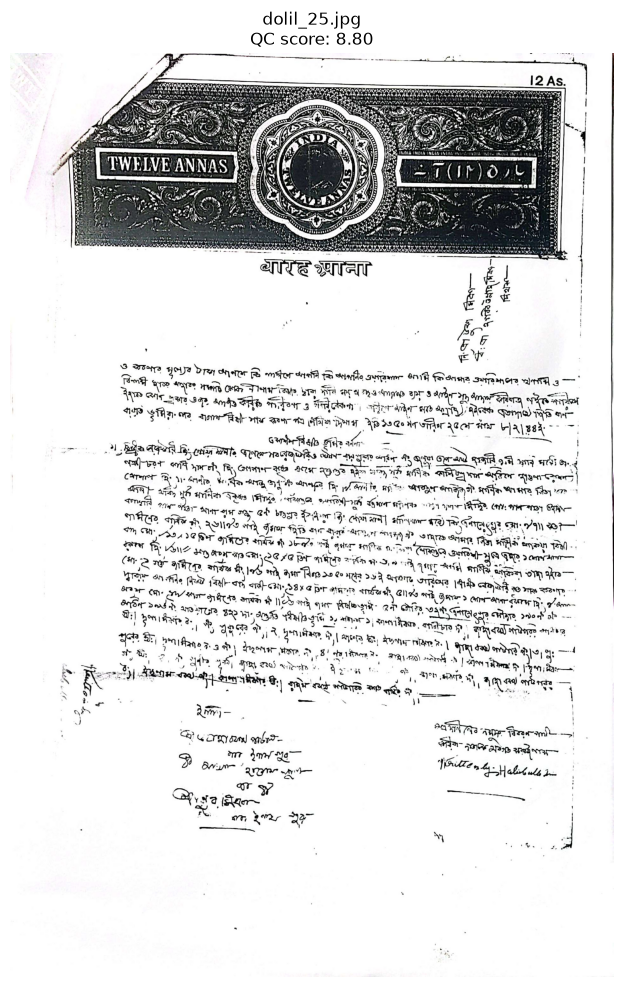

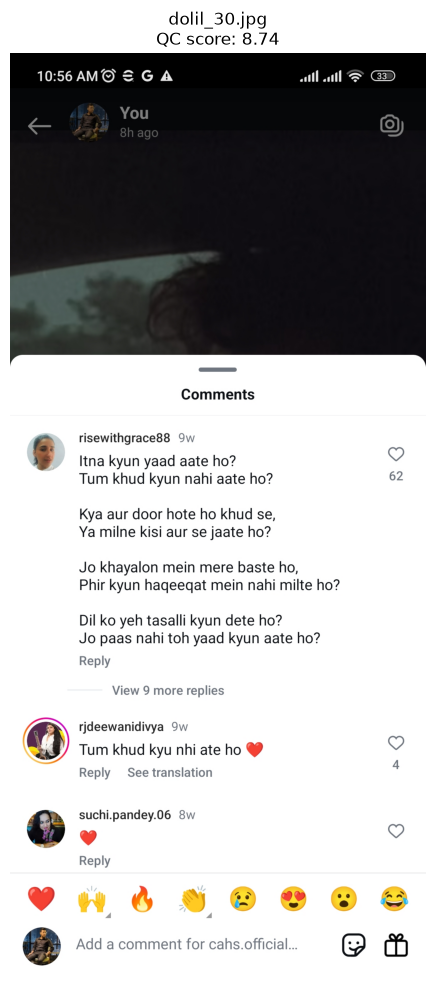

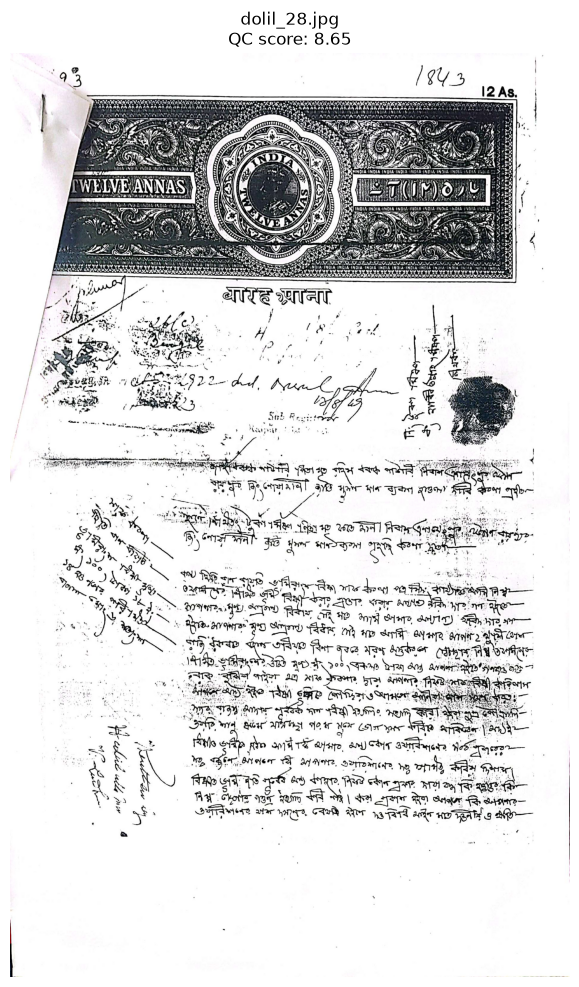

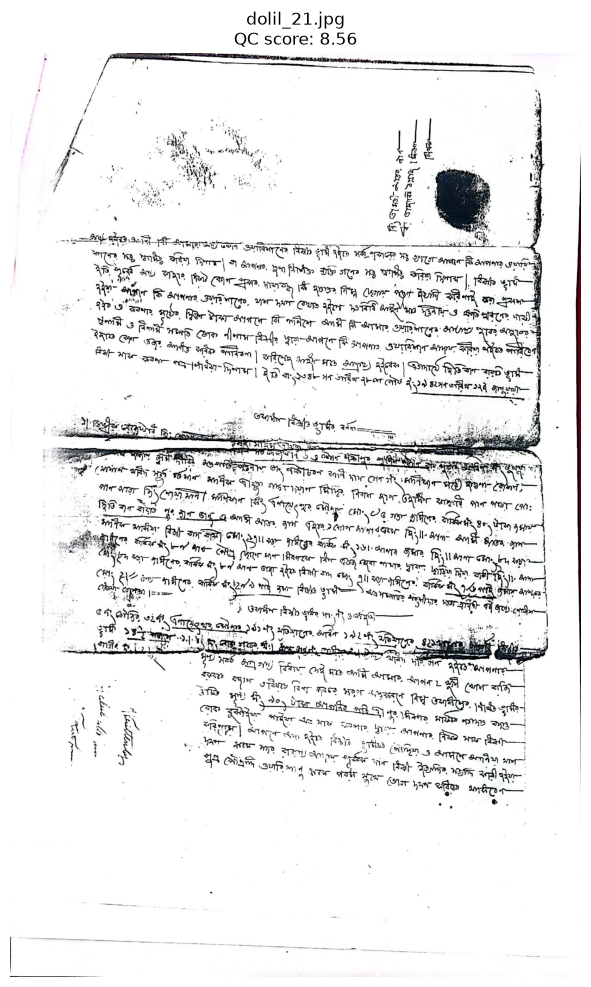

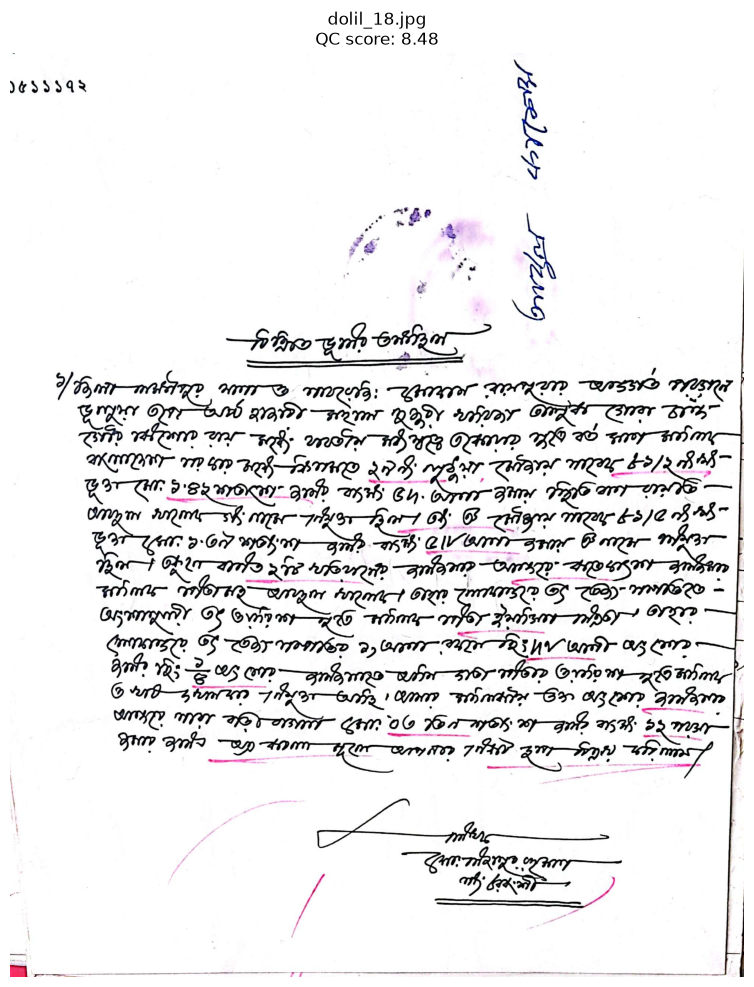

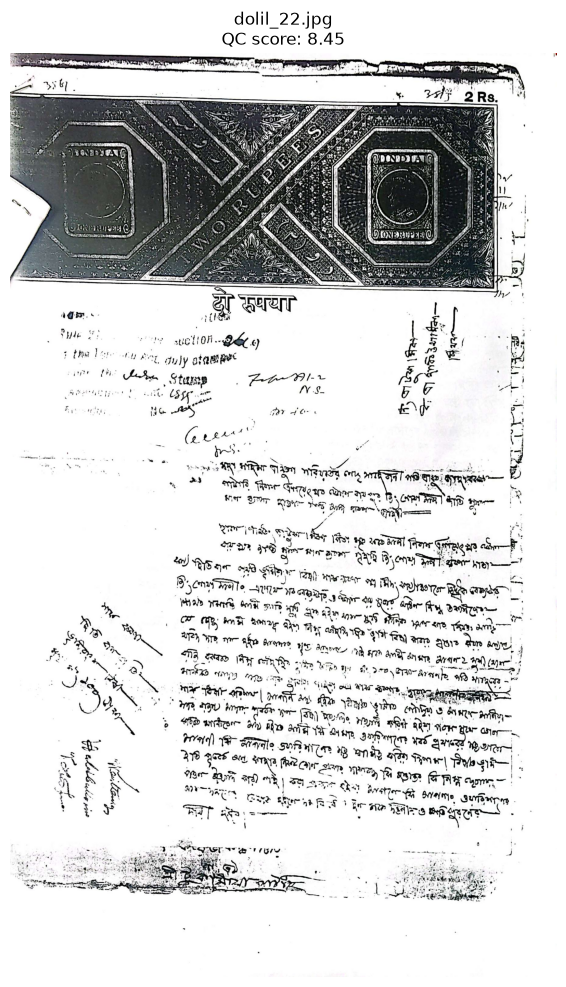

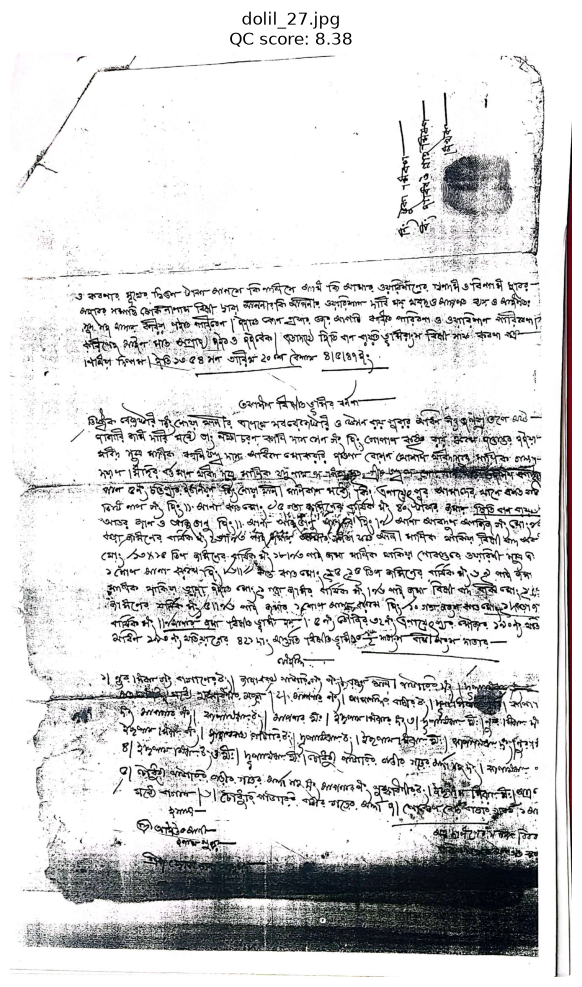

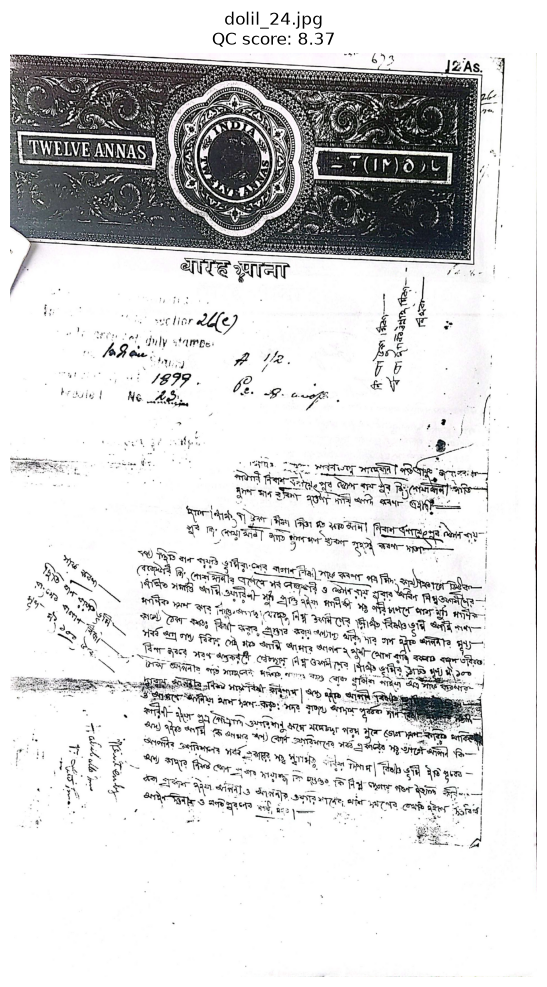

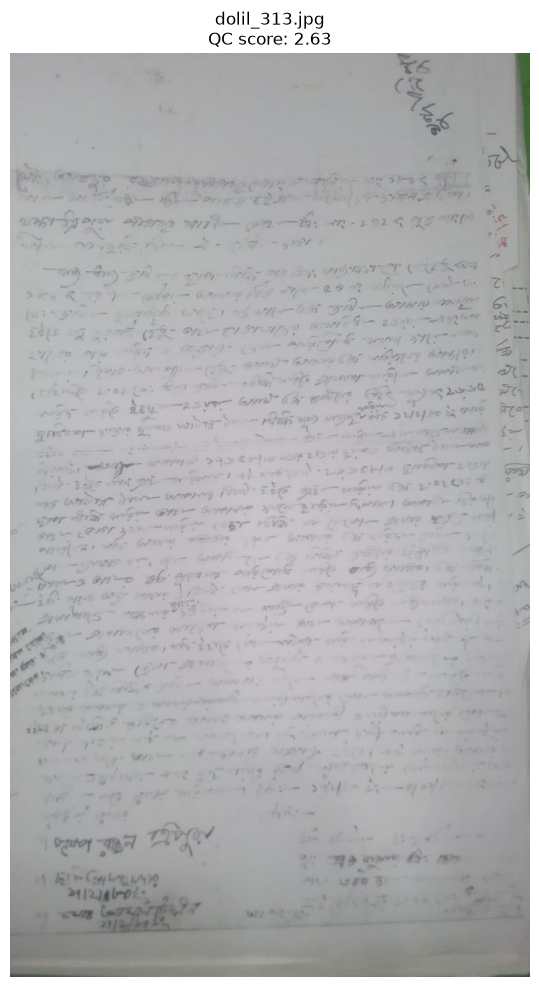

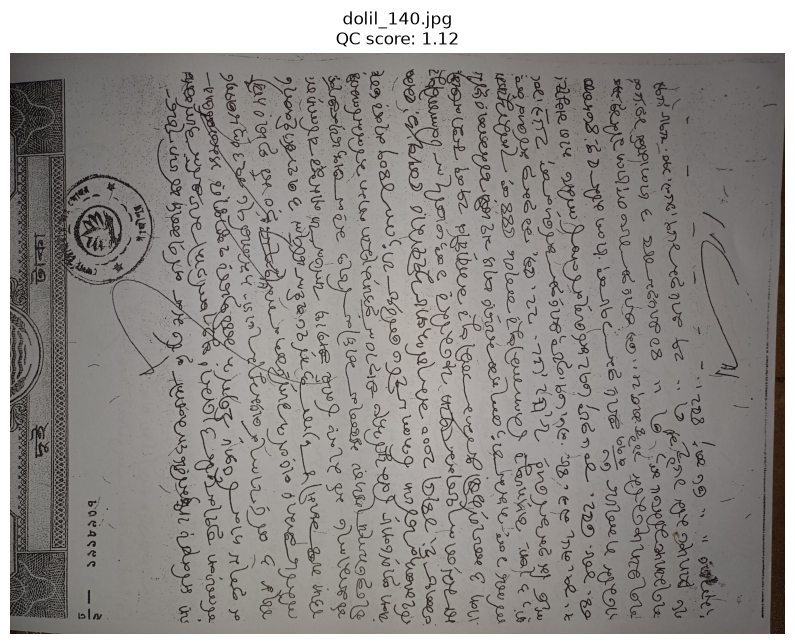

In [122]:
for file_name in audit_files:

    image = (
        audit_images[
            file_name
        ]
    )

    qc_row = (
        full_qc_df[
            full_qc_df[
                "file_name"
            ] == file_name
        ]
        .iloc[0]
    )

    plt.figure(
        figsize=(10, 12)
    )

    plt.imshow(
        image
    )

    plt.axis("off")

    plt.title(
        f"{file_name}\n"
        f"QC score: "
        f"{qc_row['relative_qc_outlier_score']:.2f}"
    )

    plt.show()

In [124]:
manual_qc_audit = {
    "dolil_25.jpg": "DEED_QUALITY_REVIEW",
    "dolil_30.jpg": "NON_DEED",
    "dolil_28.jpg": "DEED_QUALITY_REVIEW",
    "dolil_21.jpg": "DEED_QUALITY_REVIEW",
    "dolil_18.jpg": "DEED_QUALITY_REVIEW",
    "dolil_22.jpg": "DEED_QUALITY_REVIEW",
    "dolil_27.jpg": "DEED_QUALITY_REVIEW",
    "dolil_24.jpg": "DEED_QUALITY_REVIEW",

    "dolil_313.jpg":
        "DEED_QUALITY_REVIEW",

    "dolil_140.jpg":
        "DEED_OK",
}

In [125]:
audit_results = []

for file_name in audit_files:

    qc_row = (
        full_qc_df[
            full_qc_df[
                "file_name"
            ] == file_name
        ]
        .iloc[0]
    )

    audit_results.append({
        "file_name":
            file_name,

        "qc_score":
            qc_row[
                "relative_qc_outlier_score"
            ],

        "brightness":
            qc_row[
                "brightness"
            ],

        "contrast":
            qc_row[
                "contrast"
            ],

        "edge_strength":
            qc_row[
                "edge_strength"
            ],

        "entropy":
            qc_row[
                "entropy"
            ],

        "visual_label":
            manual_qc_audit[
                file_name
            ],
    })


visual_qc_audit_df = pd.DataFrame(
    audit_results
)

visual_qc_audit_df

,file_name,qc_score,brightness,contrast,edge_strength,entropy,visual_label
0,dolil_25.jpg,8.797445,218.699722,80.596657,62.281567,3.086581,DEED_QUALITY_REVIEW
1,dolil_30.jpg,8.741977,170.455856,111.685837,36.952202,3.007795,NON_DEED
2,dolil_28.jpg,8.649165,215.561081,82.240082,67.961601,3.477514,DEED_QUALITY_REVIEW
3,dolil_21.jpg,8.564904,233.933777,63.003994,57.214073,2.453723,DEED_QUALITY_REVIEW
4,dolil_18.jpg,8.479704,232.961365,65.324516,48.359989,2.332451,DEED_QUALITY_REVIEW
5,dolil_22.jpg,8.450319,208.490952,86.592468,63.848194,3.638595,DEED_QUALITY_REVIEW
6,dolil_27.jpg,8.378003,211.010986,85.612701,68.259964,3.870265,DEED_QUALITY_REVIEW
7,dolil_24.jpg,8.371714,211.211441,85.618034,61.274242,3.626863,DEED_QUALITY_REVIEW
8,dolil_313.jpg,2.630868,171.680817,16.574469,14.856104,5.888109,DEED_QUALITY_REVIEW
9,dolil_140.jpg,1.117283,128.942184,40.259766,34.088093,6.874998,DEED_OK


In [126]:
missing_labels = (
    visual_qc_audit_df[
        "visual_label"
    ]
    .isna()
    .sum()
)

print(
    "Missing manual labels:",
    missing_labels
)

Missing manual labels: 0


In [127]:
visual_qc_audit_df[
    "visual_label"
].value_counts()

visual_label
DEED_QUALITY_REVIEW    8
NON_DEED               1
DEED_OK                1
Name: count, dtype: int64

In [128]:
deed_ok_count = int(
    (
        visual_qc_audit_df[
            "visual_label"
        ] == "DEED_OK"
    ).sum()
)

quality_review_count = int(
    (
        visual_qc_audit_df[
            "visual_label"
        ]
        == "DEED_QUALITY_REVIEW"
    ).sum()
)

non_deed_count = int(
    (
        visual_qc_audit_df[
            "visual_label"
        ] == "NON_DEED"
    ).sum()
)

uncertain_count = int(
    (
        visual_qc_audit_df[
            "visual_label"
        ] == "UNCERTAIN"
    ).sum()
)

In [129]:
top8_audit_df = (
    visual_qc_audit_df[
        visual_qc_audit_df[
            "file_name"
        ].isin(
            top8_files
        )
    ]
)

top8_audit_df[
    [
        "file_name",
        "qc_score",
        "visual_label"
    ]
]

,file_name,qc_score,visual_label
0,dolil_25.jpg,8.797445,DEED_QUALITY_REVIEW
1,dolil_30.jpg,8.741977,NON_DEED
2,dolil_28.jpg,8.649165,DEED_QUALITY_REVIEW
3,dolil_21.jpg,8.564904,DEED_QUALITY_REVIEW
4,dolil_18.jpg,8.479704,DEED_QUALITY_REVIEW
5,dolil_22.jpg,8.450319,DEED_QUALITY_REVIEW
6,dolil_27.jpg,8.378003,DEED_QUALITY_REVIEW
7,dolil_24.jpg,8.371714,DEED_QUALITY_REVIEW


In [130]:
top8_problem_count = int(
    top8_audit_df[
        "visual_label"
    ].isin(
        [
            "NON_DEED",
            "DEED_QUALITY_REVIEW",
        ]
    ).sum()
)

print(
    "Top-8 actual review/problem cases:",
    top8_problem_count,
    "/",
    len(top8_audit_df)
)

Top-8 actual review/problem cases: 8 / 8


In [131]:
image_qc_policy = {
    "qc_score_role":
        "REVIEW_PRIORITIZATION_ONLY",

    "automatic_non_deed_rejection":
        False,

    "automatic_quality_rejection":
        False,

    "known_non_deed":
        [
            "dolil_30.jpg"
        ],

    "known_quality_review":
        [
            "dolil_313.jpg"
        ],

    "raw_images_modified":
        False,
}

image_qc_policy

{'qc_score_role': 'REVIEW_PRIORITIZATION_ONLY',
 'automatic_non_deed_rejection': False,
 'automatic_quality_rejection': False,
 'known_non_deed': ['dolil_30.jpg'],
 'known_quality_review': ['dolil_313.jpg'],
 'raw_images_modified': False}

In [132]:
image_qc_policy = {
    "qc_score_role":
        "REVIEW_PRIORITIZATION_ONLY",

    "automatic_non_deed_rejection":
        False,

    "automatic_quality_rejection":
        False,

    "known_non_deed":
        [
            "dolil_30.jpg"
        ],

    "known_quality_review":
        [
            "dolil_313.jpg"
        ],

    "raw_images_modified":
        False,
}

image_qc_policy

{'qc_score_role': 'REVIEW_PRIORITIZATION_ONLY',
 'automatic_non_deed_rejection': False,
 'automatic_quality_rejection': False,
 'known_non_deed': ['dolil_30.jpg'],
 'known_quality_review': ['dolil_313.jpg'],
 'raw_images_modified': False}

In [133]:
print("STEP 19H SUMMARY")
print("----------------")

print(
    "Images visually audited:",
    len(
        visual_qc_audit_df
    )
)

print(
    "Deed OK:",
    deed_ok_count
)

print(
    "Quality review:",
    quality_review_count
)

print(
    "Non-deed:",
    non_deed_count
)

print(
    "Uncertain:",
    uncertain_count
)

print(
    "Top-8 actual review/problem:",
    top8_problem_count,
    "/",
    len(
        top8_audit_df
    )
)

print(
    "Automatic QC rejection:",
    False
)

print(
    "\nQC Visual Audit: COMPLETE"
)

STEP 19H SUMMARY
----------------
Images visually audited: 10
Deed OK: 1
Quality review: 8
Non-deed: 1
Uncertain: 0
Top-8 actual review/problem: 8 / 8
Automatic QC rejection: False

QC Visual Audit: COMPLETE


# STEP 19I — Final Handwritten Image Ingestion Policy

The handwritten deed dataset was evaluated for:

- dataset integrity
- document/content quality
- orientation
- preprocessing benefit
- Bengali OCR readiness

The final policy is conservative and non-destructive.

No raw image is modified or deleted.

Automated signals are used for screening and review prioritization,
not as legal-document verification.

In [134]:
final_orientation_policy = {
    "primary_method":
        "FOUR_ANGLE_BENGALI_OCR",

    "candidate_angles":
        [0, 90, 180, 270],

    "prototype_auto_margin_threshold":
        0.10,

    "margin_at_or_above_threshold":
        "AUTO_CORRECT_CANDIDATE",

    "margin_below_threshold":
        "REVIEW",

    "osd_role":
        "SECONDARY_EVIDENCE_ONLY",

    "geometry_role":
        "WEAK_CLUE_ONLY",

    "raw_image_rotation":
        False,
}

In [135]:
final_qc_policy = {
    "relative_qc_score_role":
        "REVIEW_PRIORITIZATION_ONLY",

    "automatic_non_deed_rejection":
        False,

    "automatic_quality_rejection":
        False,

    "high_qc_score":
        "PRIORITIZE_FOR_REVIEW",

    "low_qc_score":
        "DO_NOT_ASSUME_GOOD_QUALITY",

    "manual_content_review_required":
        True,

    "raw_image_deletion":
        False,
}

In [136]:
final_preprocessing_policy = {
    "default":
        "RAW",

    "global_grayscale":
        False,

    "global_autocontrast":
        False,

    "global_sharpen":
        False,

    "faint_low_contrast_case":
        "OPTIONAL_AUTOCONTRAST_SHARP",

    "preprocessing_role":
        "CONDITIONAL_OCR_ASSISTANCE",

    "raw_images_modified":
        False,
}

In [137]:
final_handwritten_ocr_policy = {
    "engine_tested":
        "TESSERACT_BENGALI",

    "printed_document_performance":
        "USABLE_BASELINE",

    "handwritten_document_performance":
        "UNRELIABLE_FOR_VERIFIED_TRANSCRIPTION",

    "ocr_role":
        "WEAK_EXTRACTION_CANDIDATE",

    "legal_field_auto_acceptance":
        False,

    "human_verification_required":
        True,

    "fraud_decision_from_ocr_alone":
        False,
}

In [138]:
step19_evidence = {
    "dataset_images":
        653,

    "unique_image_sizes":
        54,

    "portrait_geometry":
        161,

    "landscape_geometry":
        492,

    "representative_samples":
        10,

    "representative_deed_like":
        9,

    "representative_non_deed":
        1,

    "four_angle_test_images":
        9,

    "four_angle_visually_correct":
        8,

    "orientation_visual_accuracy":
        8 / 9,

    "orientation_auto_subset":
        5,

    "orientation_auto_subset_correct":
        5,

    "orientation_auto_subset_precision":
        1.0,

    "qc_full_dataset_images":
        653,

    "qc_missing_metrics":
        0,

    "qc_visual_audit_images":
        10,

    "qc_visual_deed_ok":
        1,

    "qc_visual_quality_review":
        8,

    "qc_visual_non_deed":
        1,

    "top8_qc_problem_or_review":
        8,

    "preprocessing_test_images":
        3,

    "preprocessing_variants":
        5,

    "best_faint_improvement":
        0.019344,
}

In [139]:
step19_final_policy = {
    "orientation":
        final_orientation_policy,

    "quality_control":
        final_qc_policy,

    "preprocessing":
        final_preprocessing_policy,

    "handwritten_ocr":
        final_handwritten_ocr_policy,

    "evidence":
        step19_evidence,
}

In [140]:
step19_final_policy

{'orientation': {'primary_method': 'FOUR_ANGLE_BENGALI_OCR',
  'candidate_angles': [0, 90, 180, 270],
  'prototype_auto_margin_threshold': 0.1,
  'margin_at_or_above_threshold': 'AUTO_CORRECT_CANDIDATE',
  'margin_below_threshold': 'REVIEW',
  'osd_role': 'SECONDARY_EVIDENCE_ONLY',
  'geometry_role': 'WEAK_CLUE_ONLY',
  'raw_image_rotation': False},
 'quality_control': {'relative_qc_score_role': 'REVIEW_PRIORITIZATION_ONLY',
  'automatic_non_deed_rejection': False,
  'automatic_quality_rejection': False,
  'high_qc_score': 'PRIORITIZE_FOR_REVIEW',
  'low_qc_score': 'DO_NOT_ASSUME_GOOD_QUALITY',
  'manual_content_review_required': True,
  'raw_image_deletion': False},
 'preprocessing': {'default': 'RAW',
  'global_grayscale': False,
  'global_autocontrast': False,
  'global_sharpen': False,
  'faint_low_contrast_case': 'OPTIONAL_AUTOCONTRAST_SHARP',
  'preprocessing_role': 'CONDITIONAL_OCR_ASSISTANCE',
  'raw_images_modified': False},
 'handwritten_ocr': {'engine_tested': 'TESSERACT_BEN

In [141]:
handwritten_processing_flow = [
    "LOAD_RAW_IMAGE",
    "CONTENT_AND_QUALITY_QC",
    "FLAG_NON_DEED_OR_REVIEW_CASES",
    "FOUR_ANGLE_ORIENTATION_SCORING",
    "AUTO_CORRECT_CANDIDATE_OR_REVIEW",
    "USE_RAW_BY_DEFAULT",
    "OPTIONAL_TARGETED_PREPROCESSING",
    "OCR_ASSISTED_EXTRACTION",
    "HUMAN_VERIFICATION",
    "STRUCTURED_FIELD_OUTPUT",
]

for step_number, step in enumerate(
    handwritten_processing_flow,
    start=1
):
    print(
        step_number,
        step
    )

1 LOAD_RAW_IMAGE
2 CONTENT_AND_QUALITY_QC
3 FLAG_NON_DEED_OR_REVIEW_CASES
4 FOUR_ANGLE_ORIENTATION_SCORING
5 AUTO_CORRECT_CANDIDATE_OR_REVIEW
6 USE_RAW_BY_DEFAULT
7 OPTIONAL_TARGETED_PREPROCESSING
8 OCR_ASSISTED_EXTRACTION
9 HUMAN_VERIFICATION
10 STRUCTURED_FIELD_OUTPUT


In [142]:
HANDWRITTEN_DOCUMENT_STATUSES = [
    "DEED_READY",
    "REVIEW_CONTENT",
    "REVIEW_IMAGE_QUALITY",
    "REVIEW_ORIENTATION",
    "OCR_UNVERIFIED",
    "NON_DEED",
]

HANDWRITTEN_DOCUMENT_STATUSES

['DEED_READY',
 'REVIEW_CONTENT',
 'REVIEW_IMAGE_QUALITY',
 'REVIEW_ORIENTATION',
 'OCR_UNVERIFIED',
 'NON_DEED']

In [143]:
step19_findings = pd.DataFrame(
    [
        {
            "component":
                "Dataset QC",

            "finding":
                "653 images processed with no missing QC metrics",

            "decision":
                "Dataset usable with QC layer",
        },

        {
            "component":
                "Content QC",

            "finding":
                "At least one obvious non-deed outlier identified",

            "decision":
                "Content screening required",
        },

        {
            "component":
                "QC Outlier Score",

            "finding":
                "Top-8 reviewed outliers were all review/problem cases",

            "decision":
                "Use for review prioritization only",
        },

        {
            "component":
                "QC Limitation",

            "finding":
                "Low-score faint image still required quality review",

            "decision":
                "Do not use single automatic threshold",
        },

        {
            "component":
                "Orientation",

            "finding":
                "Four-angle OCR achieved 8/9 visual correctness",

            "decision":
                "Use confidence-gated orientation",
        },

        {
            "component":
                "OSD",

            "finding":
                "Low confidence and unreliable script detection",

            "decision":
                "Secondary evidence only",
        },

        {
            "component":
                "Preprocessing",

            "finding":
                "Faint case improved only about 1.9%",

            "decision":
                "No global preprocessing",
        },

        {
            "component":
                "Handwritten OCR",

            "finding":
                "Bengali OCR output remained highly noisy",

            "decision":
                "Human verification required",
        },
    ]
)

step19_findings

,component,finding,decision
0,Dataset QC,653 images processed with no missing QC metrics,Dataset usable with QC layer
1,Content QC,At least one obvious non-deed outlier identified,Content screening required
2,QC Outlier Score,Top-8 reviewed outliers were all review/proble...,Use for review prioritization only
3,QC Limitation,Low-score faint image still required quality r...,Do not use single automatic threshold
4,Orientation,Four-angle OCR achieved 8/9 visual correctness,Use confidence-gated orientation
5,OSD,Low confidence and unreliable script detection,Secondary evidence only
6,Preprocessing,Faint case improved only about 1.9%,No global preprocessing
7,Handwritten OCR,Bengali OCR output remained highly noisy,Human verification required


In [144]:
print("STEP 19I SUMMARY")
print("----------------")

print(
    "Dataset images:",
    step19_evidence[
        "dataset_images"
    ]
)

print(
    "Full QC coverage:",
    step19_evidence[
        "qc_full_dataset_images"
    ],
    "/",
    step19_evidence[
        "dataset_images"
    ]
)

print(
    "Representative non-deed detected:",
    step19_evidence[
        "representative_non_deed"
    ]
)

print(
    "Four-angle visual accuracy:",
    round(
        step19_evidence[
            "orientation_visual_accuracy"
        ],
        3
    )
)

print(
    "Conservative auto subset precision:",
    step19_evidence[
        "orientation_auto_subset_precision"
    ]
)

print(
    "Top-8 QC review/problem:",
    step19_evidence[
        "top8_qc_problem_or_review"
    ],
    "/ 8"
)

print(
    "Global preprocessing:",
    False
)

print(
    "Handwritten OCR auto-verification:",
    False
)

print(
    "Raw images modified:",
    False
)

print(
    "\nSTEP 19 — HANDWRITTEN IMAGE INGESTION POLICY COMPLETE"
)

STEP 19I SUMMARY
----------------
Dataset images: 653
Full QC coverage: 653 / 653
Representative non-deed detected: 1
Four-angle visual accuracy: 0.889
Conservative auto subset precision: 1.0
Top-8 QC review/problem: 8 / 8
Global preprocessing: False
Handwritten OCR auto-verification: False
Raw images modified: False

STEP 19 — HANDWRITTEN IMAGE INGESTION POLICY COMPLETE


# STEP 20 — Handwritten Bengali OCR Baseline

This phase evaluates handwritten Bengali OCR using manually verified
ground-truth text.

OCR confidence alone is not treated as transcription accuracy.

Initial benchmark images:

- normal-quality deed
- faint / low-contrast deed
- visually unusual but valid deed

Evaluation will use short manually verified text regions before any
large-scale OCR processing.

In [145]:
ocr_benchmark_files = [
    "dolil_140.jpg",
    "dolil_313.jpg",
    "dolil_32.jpg",
]

ocr_benchmark_images = {}

for file_name in ocr_benchmark_files:

    image = get_sample_image(
        file_name
    )

    angle = get_best_angle(
        file_name
    )

    corrected = rotate_candidate(
        image,
        angle
    )

    ocr_benchmark_images[
        file_name
    ] = corrected


print(
    "Benchmark images:",
    len(
        ocr_benchmark_images
    )
)

Benchmark images: 3


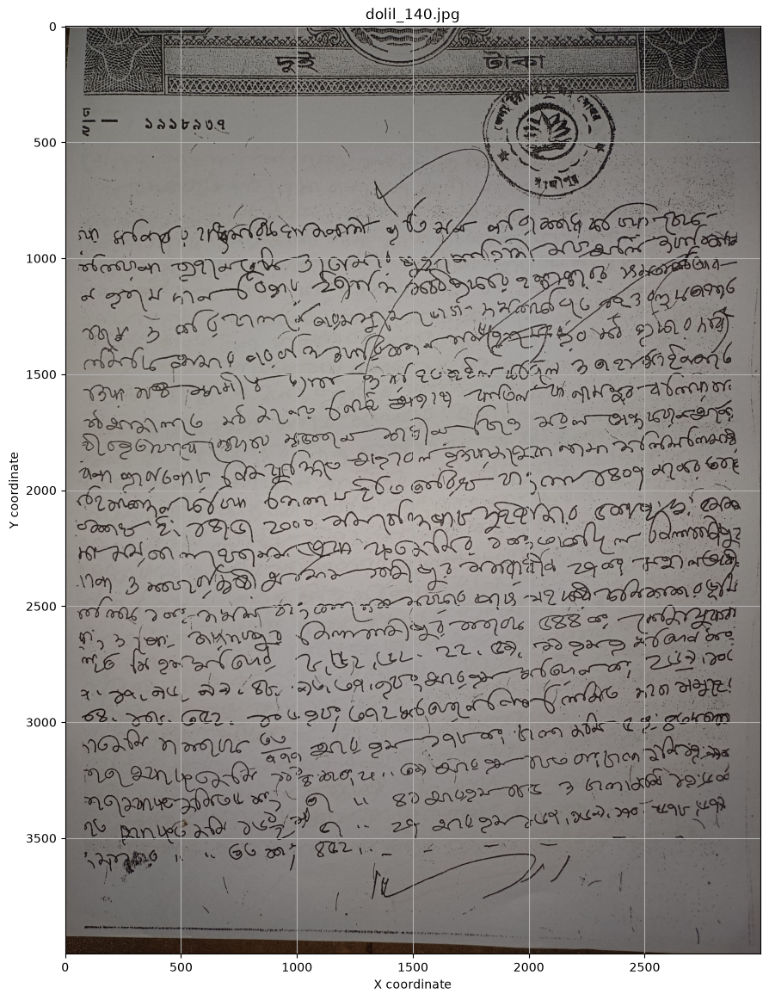

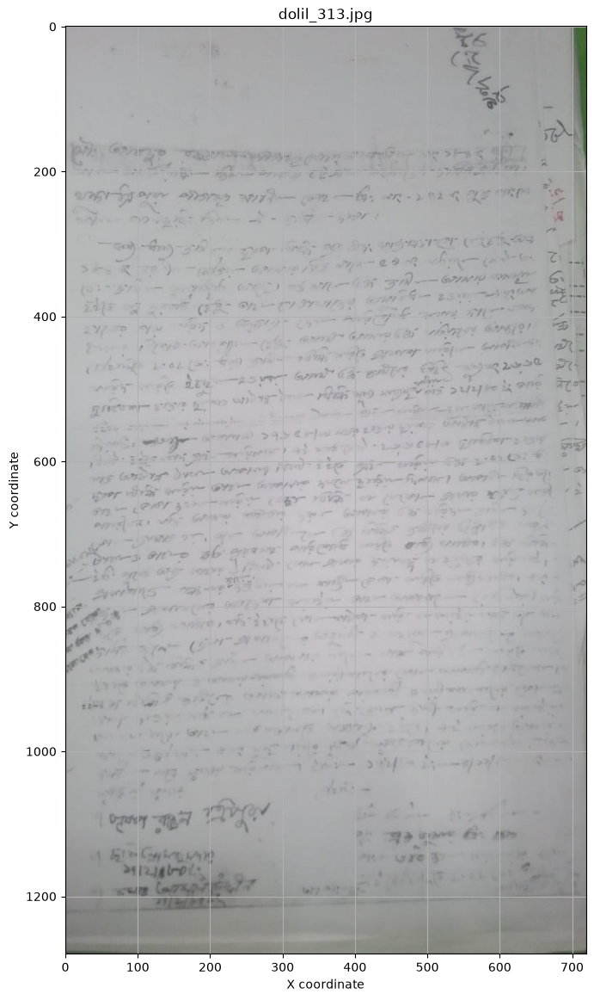

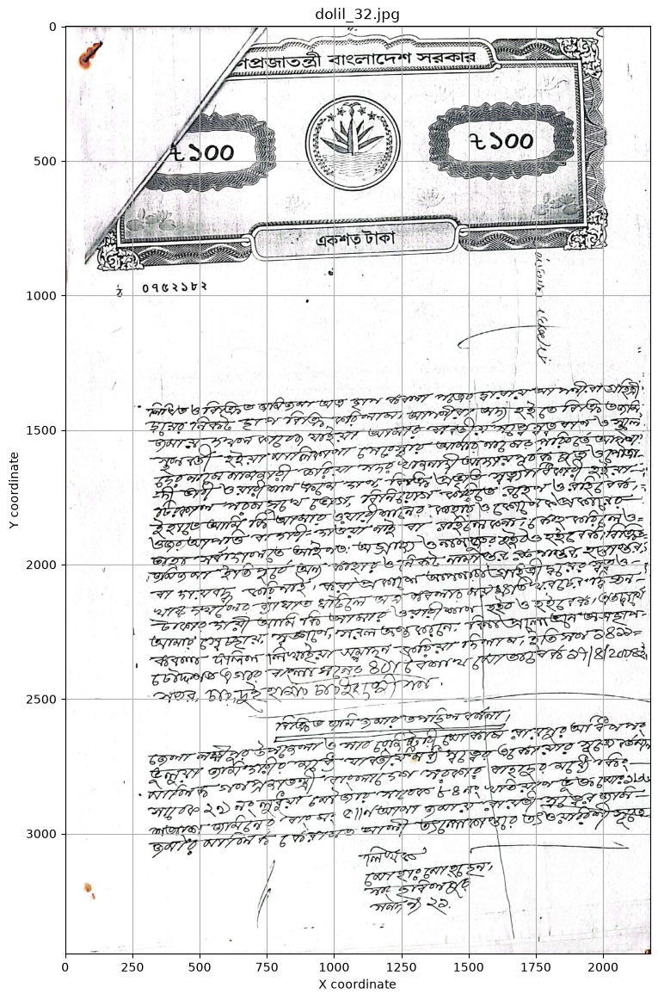

In [146]:
for file_name, image in (
    ocr_benchmark_images.items()
):

    plt.figure(
        figsize=(12, 14)
    )

    plt.imshow(
        image
    )

    plt.title(
        file_name
    )

    plt.xlabel(
        "X coordinate"
    )

    plt.ylabel(
        "Y coordinate"
    )

    plt.grid()

    plt.show()

In [147]:
def show_crop(
    file_name,
    left,
    top,
    right,
    bottom
):

    image = (
        ocr_benchmark_images[
            file_name
        ]
    )

    crop = image.crop(
        (
            left,
            top,
            right,
            bottom
        )
    )

    plt.figure(
        figsize=(14, 5)
    )

    plt.imshow(
        crop
    )

    plt.axis(
        "off"
    )

    plt.title(
        file_name
    )

    plt.show()

    return crop

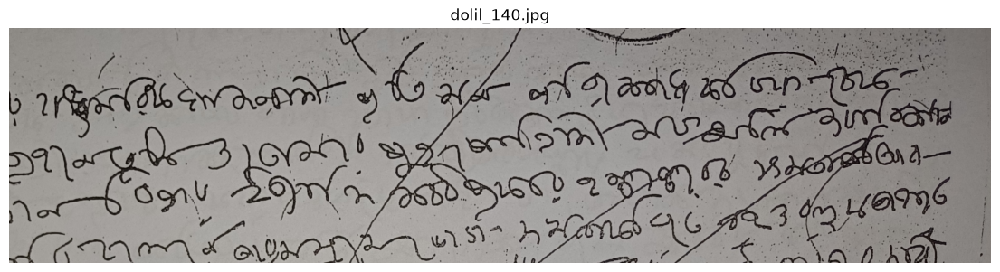

In [148]:
test_crop = show_crop(
    "dolil_140.jpg",
    left=500,
    top=700,
    right=3000,
    bottom=1300
)

In [151]:
def create_horizontal_regions(
    image,
    side_margin=0.05
):
    width, height = image.size

    left = int(
        width * side_margin
    )

    right = int(
        width * (
            1 - side_margin
        )
    )

    region_height = (
        height // 4
    )

    regions = {}

    for region_number in range(4):

        top = (
            region_number
            * region_height
        )

        if region_number == 3:
            bottom = height
        else:
            bottom = (
                (region_number + 1)
                * region_height
            )

        regions[
            region_number + 1
        ] = image.crop(
            (
                left,
                top,
                right,
                bottom
            )
        )

    return regions


dolil_140.jpg


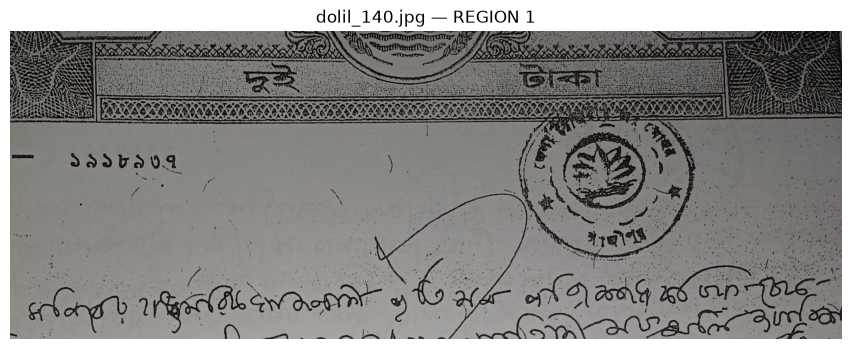

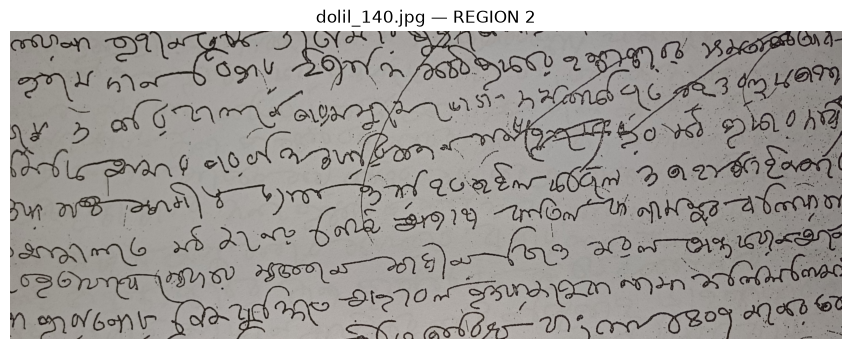

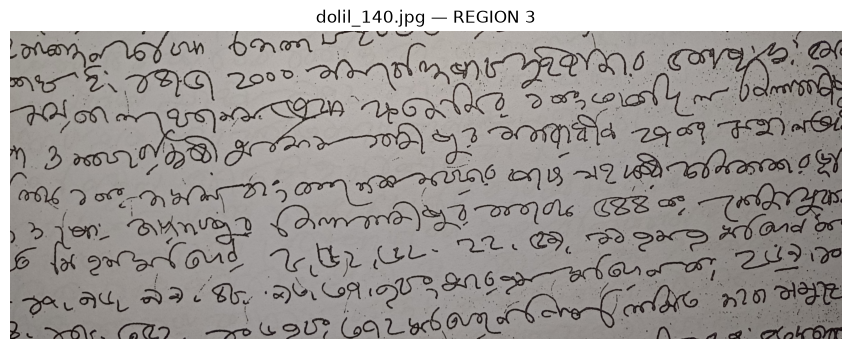

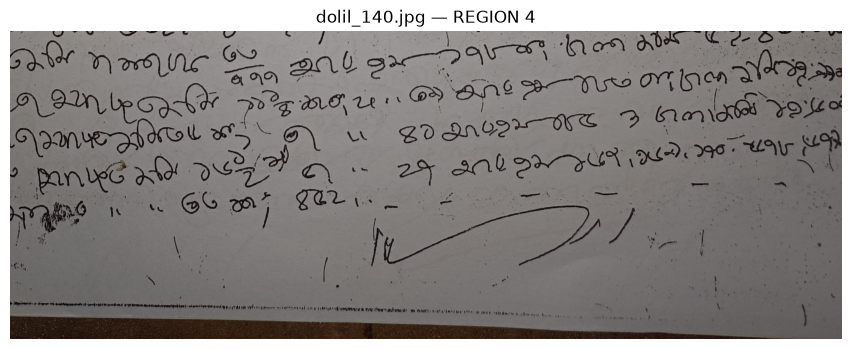


dolil_313.jpg


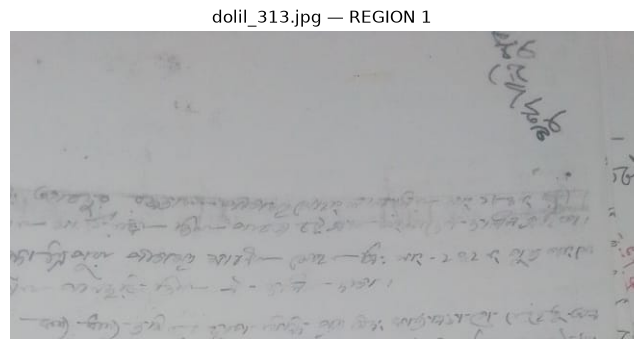

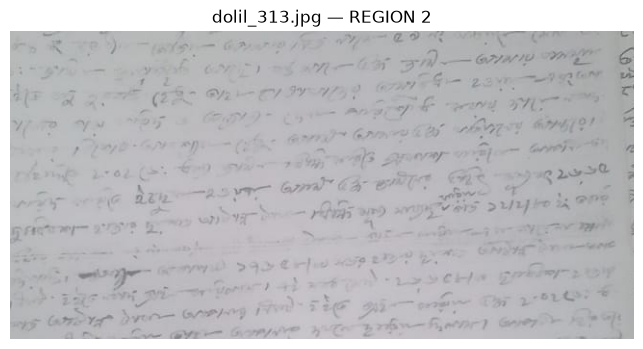

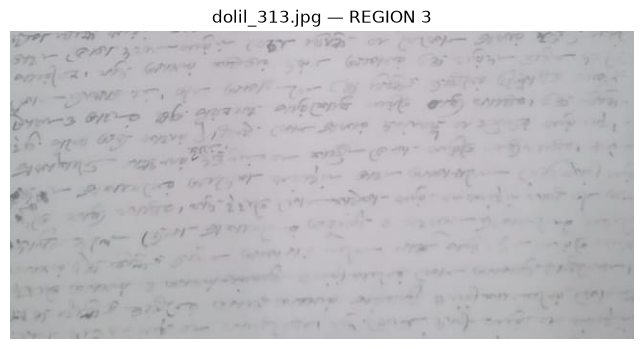

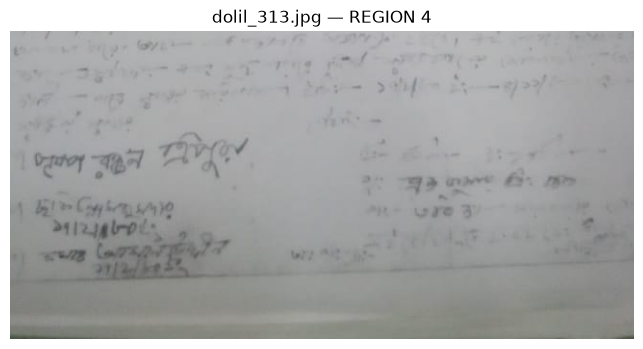


dolil_32.jpg


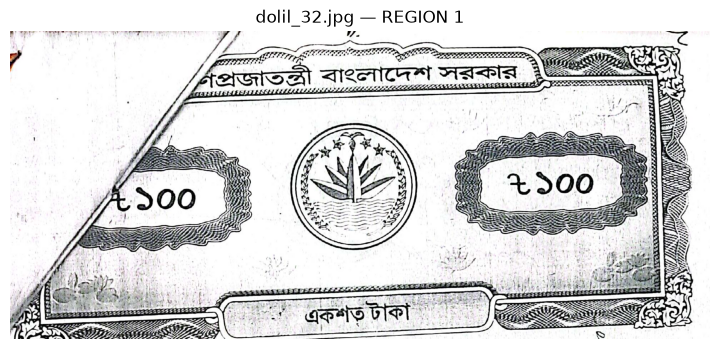

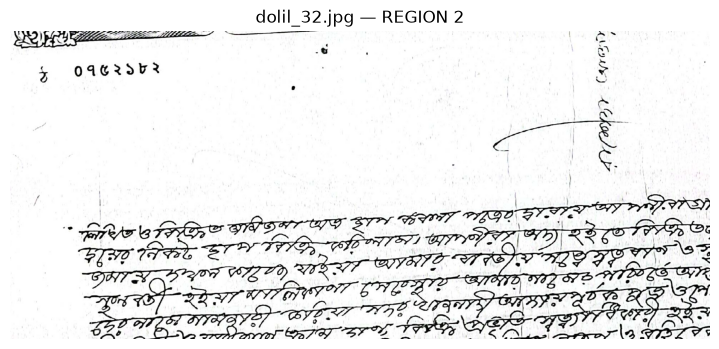

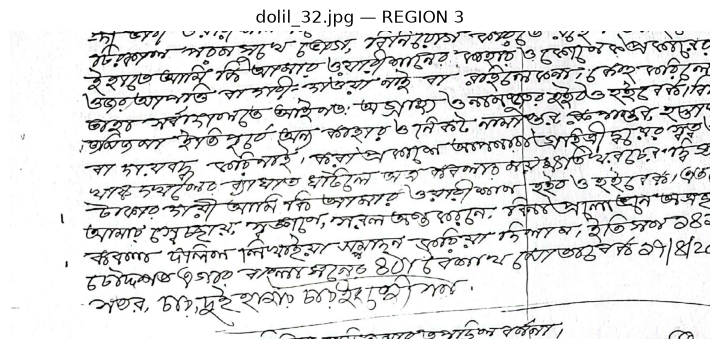

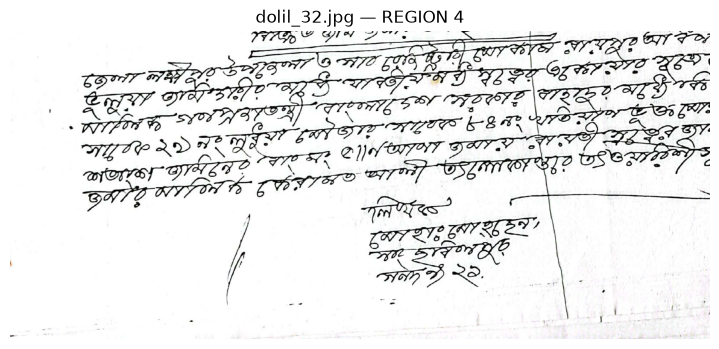

In [152]:
benchmark_regions = {}

for file_name, image in (
    ocr_benchmark_images.items()
):

    regions = (
        create_horizontal_regions(
            image
        )
    )

    benchmark_regions[
        file_name
    ] = regions

    print(
        "\n",
        "=" * 70
    )

    print(
        file_name
    )

    print(
        "=" * 70
    )

    for region_number, region in (
        regions.items()
    ):

        plt.figure(
            figsize=(14, 4)
        )

        plt.imshow(
            region
        )

        plt.axis(
            "off"
        )

        plt.title(
            f"{file_name} — REGION {region_number}"
        )

        plt.show()

In [153]:
selected_regions = {
    "dolil_140.jpg": 2,
    "dolil_313.jpg": 3,
    "dolil_32.jpg": 1,
}

In [154]:
benchmark_crops = {}

for file_name, region_number in (
    selected_regions.items()
):

    benchmark_crops[
        file_name
    ] = (
        benchmark_regions[
            file_name
        ][
            region_number
        ]
    )


print(
    "Benchmark crops:",
    len(
        benchmark_crops
    )
)

Benchmark crops: 3


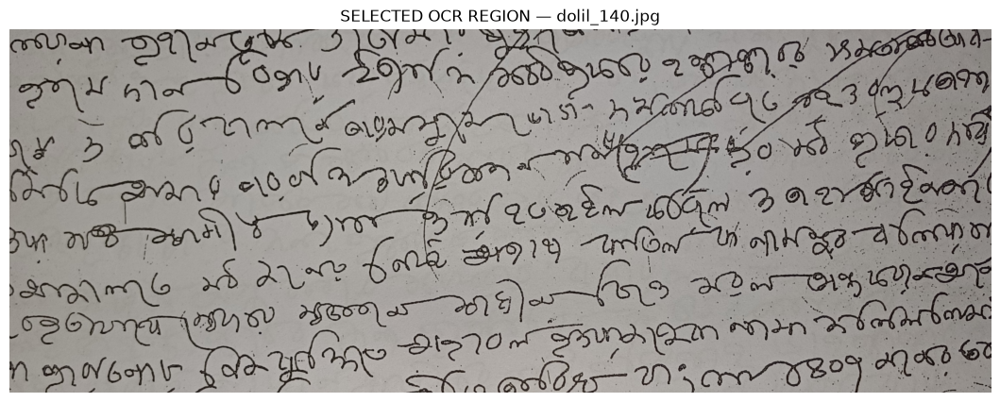

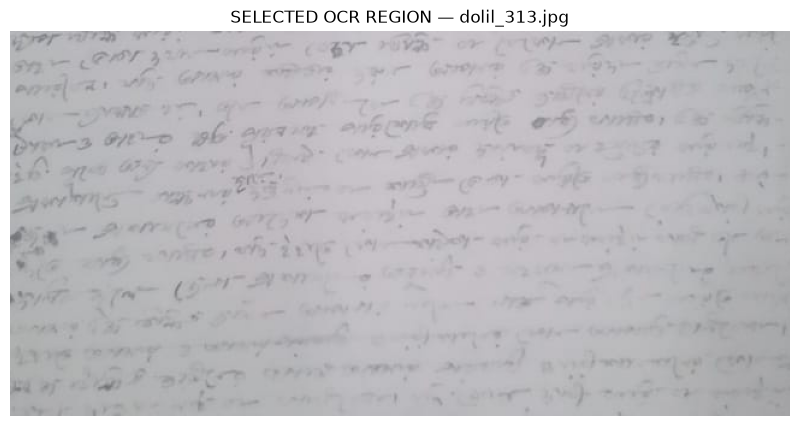

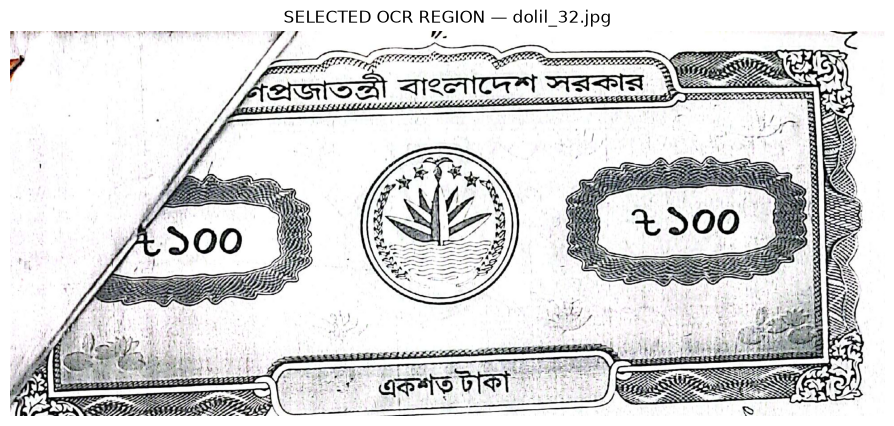

In [155]:
for file_name, crop in (
    benchmark_crops.items()
):

    plt.figure(
        figsize=(14, 5)
    )

    plt.imshow(
        crop
    )

    plt.axis(
        "off"
    )

    plt.title(
        f"SELECTED OCR REGION — {file_name}"
    )

    plt.show()

In [156]:
selected_regions = {
    "dolil_140.jpg": 2,
    "dolil_313.jpg": 3,
    "dolil_32.jpg": 3,
}

In [157]:
benchmark_crops = {}

for file_name, region_number in selected_regions.items():

    benchmark_crops[file_name] = (
        benchmark_regions[file_name][region_number]
    )

print(
    "Benchmark crops:",
    len(benchmark_crops)
)

Benchmark crops: 3


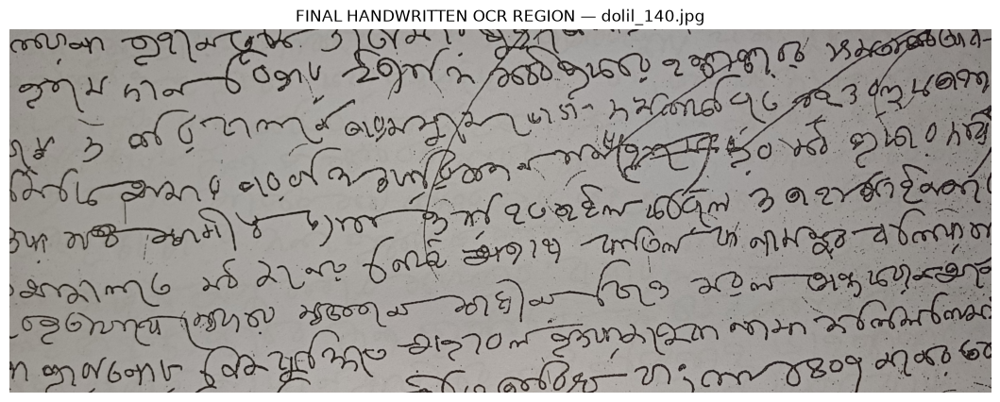

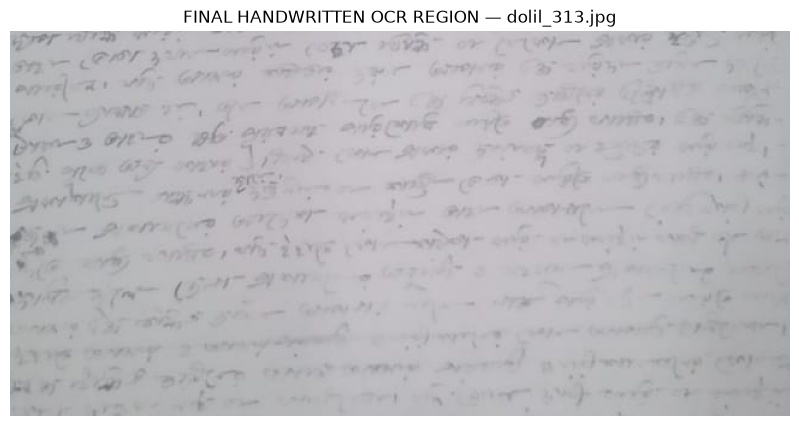

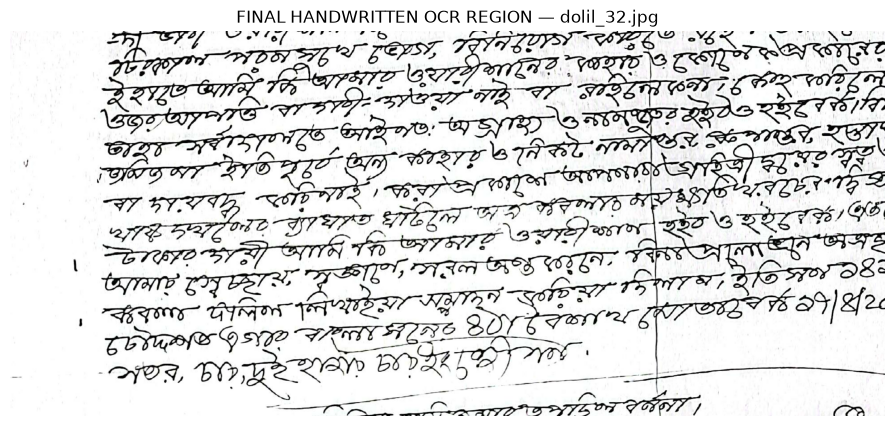

In [158]:
for file_name, crop in benchmark_crops.items():

    plt.figure(figsize=(14, 5))

    plt.imshow(crop)

    plt.axis("off")

    plt.title(
        f"FINAL HANDWRITTEN OCR REGION — {file_name}"
    )

    plt.show()

In [160]:
def split_into_line_bands(
    image,
    bands=8
):
    width, height = image.size

    band_height = height // bands

    outputs = {}

    for i in range(bands):

        top = i * band_height

        bottom = (
            height
            if i == bands - 1
            else (i + 1) * band_height
        )

        outputs[i + 1] = image.crop(
            (
                0,
                top,
                width,
                bottom
            )
        )

    return outputs

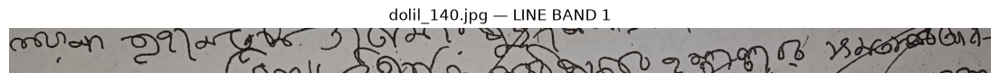

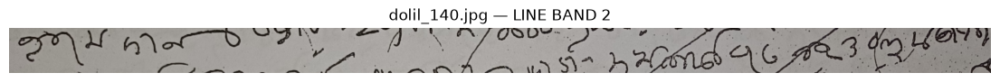

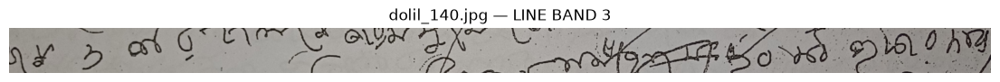

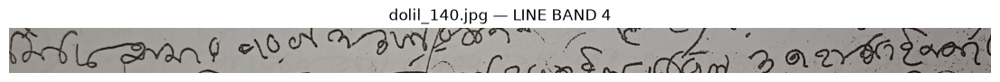

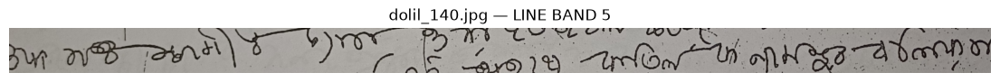

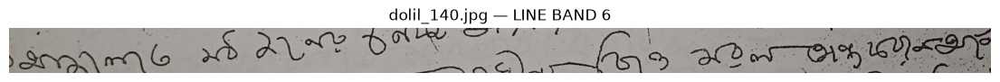

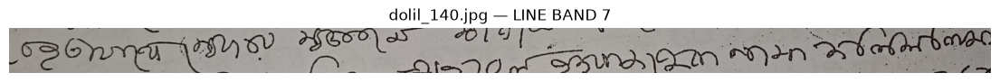

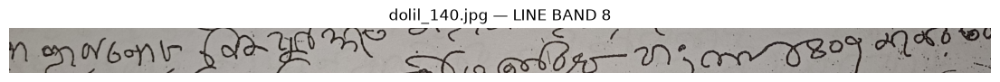

In [161]:
line_regions_140 = split_into_line_bands(
    benchmark_crops[
        "dolil_140.jpg"
    ],
    bands=8
)

for line_no, line_image in (
    line_regions_140.items()
):

    plt.figure(figsize=(14, 2.5))

    plt.imshow(line_image)

    plt.axis("off")

    plt.title(
        f"dolil_140.jpg — LINE BAND {line_no}"
    )

    plt.show()

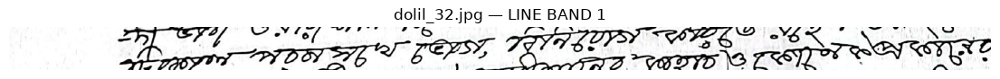

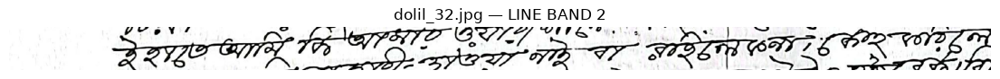

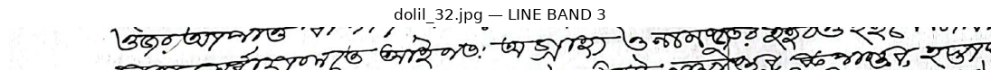

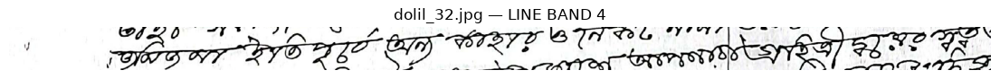

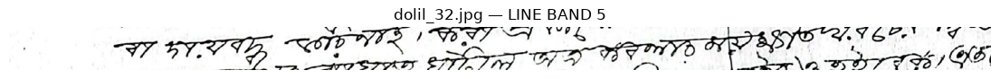

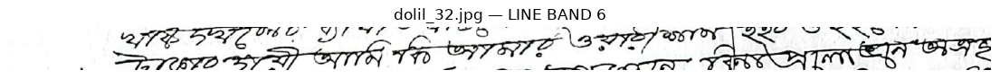

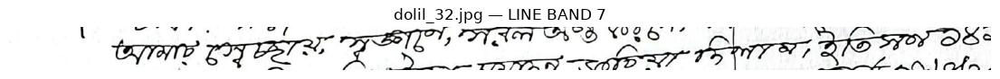

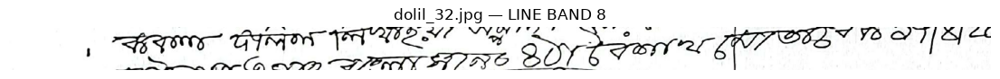

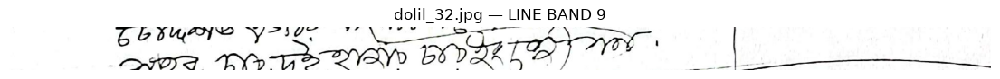

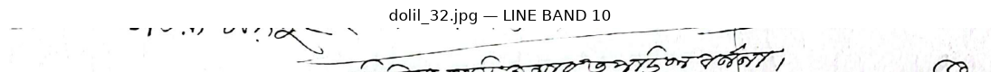

In [162]:
line_regions_32 = split_into_line_bands(
    benchmark_crops[
        "dolil_32.jpg"
    ],
    bands=10
)

for line_no, line_image in (
    line_regions_32.items()
):

    plt.figure(figsize=(14, 2.5))

    plt.imshow(line_image)

    plt.axis("off")

    plt.title(
        f"dolil_32.jpg — LINE BAND {line_no}"
    )

    plt.show()

In [164]:
candidate_lines = {
    "dolil_140.jpg": line_regions_140[6],
    "dolil_32.jpg": line_regions_32[8],
}

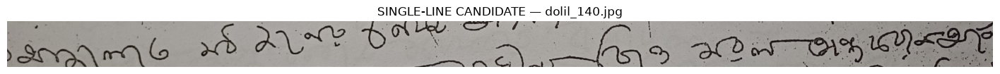

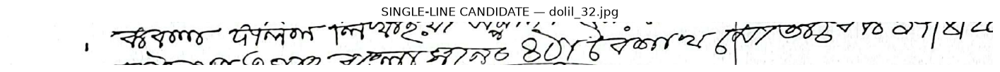

In [165]:
for file_name, image in candidate_lines.items():

    plt.figure(figsize=(18, 4))

    plt.imshow(image)

    plt.axis("off")

    plt.title(
        f"SINGLE-LINE CANDIDATE — {file_name}"
    )

    plt.show()

In [166]:
def crop_vertical_fraction(
    image,
    top_fraction,
    bottom_fraction
):
    width, height = image.size

    top = int(
        height * top_fraction
    )

    bottom = int(
        height * bottom_fraction
    )

    return image.crop(
        (
            0,
            top,
            width,
            bottom
        )
    )

In [167]:
single_line_140 = crop_vertical_fraction(
    candidate_lines["dolil_140.jpg"],
    0.15,
    0.85
)

single_line_32 = crop_vertical_fraction(
    candidate_lines["dolil_32.jpg"],
    0.15,
    0.85
)

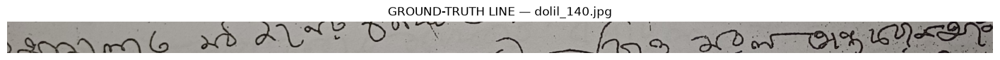

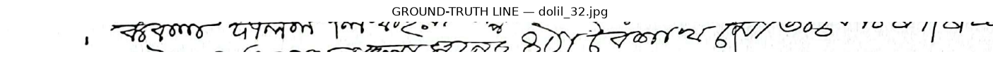

In [168]:
single_line_images = {
    "dolil_140.jpg": single_line_140,
    "dolil_32.jpg": single_line_32,
}

for file_name, image in single_line_images.items():

    plt.figure(figsize=(18, 3))

    plt.imshow(image)

    plt.axis("off")

    plt.title(
        f"GROUND-TRUTH LINE — {file_name}"
    )

    plt.show()

In [169]:
single_line_140 = crop_vertical_fraction(
    candidate_lines["dolil_140.jpg"],
    0.02,
    0.98
)

In [170]:
single_line_32 = crop_vertical_fraction(
    candidate_lines["dolil_32.jpg"],
    0.02,
    0.98
)

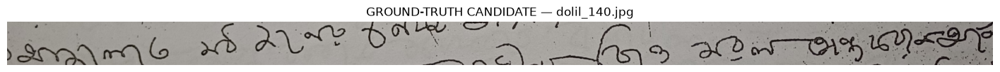

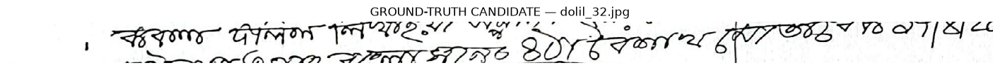

In [171]:
single_line_images = {
    "dolil_140.jpg": single_line_140,
    "dolil_32.jpg": single_line_32,
}

for file_name, image in single_line_images.items():

    plt.figure(figsize=(18, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"GROUND-TRUTH CANDIDATE — {file_name}"
    )
    plt.show()

In [172]:
handwritten_ground_truth_status = {
    "dolil_140.jpg": {
        "quality_case": "NORMAL_HANDWRITING",
        "confident_ground_truth": False,
        "reason": "HANDWRITING_NOT_RELIABLY_TRANSCRIBABLE",
        "evaluation": "QUALITATIVE_ONLY",
    },

    "dolil_313.jpg": {
        "quality_case": "FAINT_HANDWRITING",
        "confident_ground_truth": False,
        "reason": "SEVERELY_FAINT",
        "evaluation": "QUALITATIVE_ONLY",
    },

    "dolil_32.jpg": {
        "quality_case": "DENSE_HANDWRITING",
        "confident_ground_truth": False,
        "reason": "HANDWRITING_NOT_RELIABLY_TRANSCRIBABLE",
        "evaluation": "QUALITATIVE_ONLY",
    },
}

handwritten_ground_truth_status

{'dolil_140.jpg': {'quality_case': 'NORMAL_HANDWRITING',
  'confident_ground_truth': False,
  'reason': 'HANDWRITING_NOT_RELIABLY_TRANSCRIBABLE',
  'evaluation': 'QUALITATIVE_ONLY'},
 'dolil_313.jpg': {'quality_case': 'FAINT_HANDWRITING',
  'confident_ground_truth': False,
  'reason': 'SEVERELY_FAINT',
  'evaluation': 'QUALITATIVE_ONLY'},
 'dolil_32.jpg': {'quality_case': 'DENSE_HANDWRITING',
  'confident_ground_truth': False,
  'reason': 'HANDWRITING_NOT_RELIABLY_TRANSCRIBABLE',
  'evaluation': 'QUALITATIVE_ONLY'}}

In [173]:
print("STEP 20B SUMMARY")
print("----------------")

print("Handwritten cases reviewed: 3")

print(
    "Reliable handwritten ground truth:",
    sum(
        item["confident_ground_truth"]
        for item in handwritten_ground_truth_status.values()
    )
)

print(
    "Qualitative-only cases:",
    sum(
        item["evaluation"] == "QUALITATIVE_ONLY"
        for item in handwritten_ground_truth_status.values()
    )
)

print(
    "CER/WER handwritten benchmark:",
    "NOT_JUSTIFIED"
)

print(
    "\nGround-Truth Availability Assessment: COMPLETE"
)

STEP 20B SUMMARY
----------------
Handwritten cases reviewed: 3
Reliable handwritten ground truth: 0
Qualitative-only cases: 3
CER/WER handwritten benchmark: NOT_JUSTIFIED

Ground-Truth Availability Assessment: COMPLETE


# STEP 20C — Handwritten Bengali OCR Configuration Stress Test

Reliable handwritten ground truth was not available for the selected
legacy deed samples.

Therefore CER/WER is not reported.

Instead, multiple Tesseract page-segmentation configurations are tested
as a qualitative OCR stress test.

Metrics such as OCR confidence, Bengali character count, and token count
are treated only as usability indicators, not transcription accuracy.

In [174]:
import os
import pytesseract

pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

CUSTOM_TESSDATA = (
    r"D:\BhumiGuard-BD\tessdata"
)

os.environ[
    "TESSDATA_PREFIX"
] = CUSTOM_TESSDATA

print(
    "Bengali available:",
    "ben" in pytesseract.get_languages(
        config=""
    )
)

Bengali available: True


In [175]:
psm_configs = [
    3,
    4,
    6,
    7,
    11,
    13,
]

print(
    "PSM configurations:",
    psm_configs
)

PSM configurations: [3, 4, 6, 7, 11, 13]


In [176]:
from pytesseract import Output
import pandas as pd
import numpy as np


def handwritten_ocr_metrics(
    image,
    psm
):

    data = (
        pytesseract.image_to_data(
            image,
            lang="ben",
            config=f"--psm {psm}",
            output_type=Output.DATAFRAME
        )
    )

    valid = data[
        (
            data["conf"] >= 0
        )
        &
        (
            data["text"]
            .fillna("")
            .str.strip()
            != ""
        )
    ].copy()

    if len(valid) == 0:

        return {
            "tokens": 0,
            "mean_conf": 0.0,
            "median_conf": 0.0,
            "text_chars": 0,
            "bengali_chars": 0,
            "bengali_ratio": 0.0,
            "text": "",
        }

    text = " ".join(
        valid["text"]
        .astype(str)
        .tolist()
    )

    bengali_chars = (
        count_bengali_chars(
            text
        )
    )

    non_space_chars = sum(
        not char.isspace()
        for char in text
    )

    bengali_ratio = (
        bengali_chars
        / non_space_chars
        if non_space_chars > 0
        else 0.0
    )

    return {
        "tokens":
            len(valid),

        "mean_conf":
            float(
                valid["conf"].mean()
            ),

        "median_conf":
            float(
                valid["conf"].median()
            ),

        "text_chars":
            len(text),

        "bengali_chars":
            bengali_chars,

        "bengali_ratio":
            bengali_ratio,

        "text":
            text,
    }

In [177]:
def prepare_stress_test_image(
    image,
    max_side=2200
):

    output = image.copy()

    output.thumbnail(
        (
            max_side,
            max_side
        )
    )

    return output

In [178]:
benchmark_crops.keys()

dict_keys(['dolil_140.jpg', 'dolil_313.jpg', 'dolil_32.jpg'])

In [179]:
print(
    list(
        benchmark_crops.keys()
    )
)

['dolil_140.jpg', 'dolil_313.jpg', 'dolil_32.jpg']


In [180]:
psm_results = []

psm_text_outputs = {}


for file_name, crop in (
    benchmark_crops.items()
):

    prepared = (
        prepare_stress_test_image(
            crop
        )
    )

    for psm in psm_configs:

        metrics = (
            handwritten_ocr_metrics(
                prepared,
                psm
            )
        )

        psm_text_outputs[
            (
                file_name,
                psm
            )
        ] = metrics["text"]

        psm_results.append({
            "file_name":
                file_name,

            "psm":
                psm,

            "tokens":
                metrics[
                    "tokens"
                ],

            "mean_conf":
                metrics[
                    "mean_conf"
                ],

            "median_conf":
                metrics[
                    "median_conf"
                ],

            "text_chars":
                metrics[
                    "text_chars"
                ],

            "bengali_chars":
                metrics[
                    "bengali_chars"
                ],

            "bengali_ratio":
                metrics[
                    "bengali_ratio"
                ],
        })

In [181]:
psm_results_df = pd.DataFrame(
    psm_results
)

print(
    "Stress tests:",
    len(
        psm_results_df
    )
)

psm_results_df

Stress tests: 18


,file_name,psm,tokens,mean_conf,median_conf,text_chars,bengali_chars,bengali_ratio
0,dolil_140.jpg,3,3,33.004957,31.238121,7,5,1.000000
1,dolil_140.jpg,4,3,33.004957,31.238121,7,5,1.000000
2,dolil_140.jpg,6,26,22.239356,24.713700,96,63,0.887324
3,dolil_140.jpg,7,3,15.913704,20.563904,9,7,1.000000
4,dolil_140.jpg,11,55,36.759002,40.133118,207,122,0.797386
5,dolil_140.jpg,13,1,0.000000,0.000000,2,2,1.000000
6,dolil_313.jpg,3,0,0.000000,0.000000,0,0,0.000000
7,dolil_313.jpg,4,0,0.000000,0.000000,0,0,0.000000
8,dolil_313.jpg,6,70,29.387263,34.107922,294,188,0.835556
9,dolil_313.jpg,7,0,0.000000,0.000000,0,0,0.000000


In [182]:
def ocr_usability_score(
    bengali_chars,
    mean_conf,
    tokens,
    bengali_ratio
):

    return (
        bengali_chars
        *
        max(
            mean_conf,
            0
        )
        *
        max(
            tokens,
            1
        ) ** 0.5
        *
        max(
            bengali_ratio,
            0
        )
    )

In [183]:
psm_results_df[
    "usability_score"
] = (
    psm_results_df.apply(
        lambda row:
            ocr_usability_score(
                row[
                    "bengali_chars"
                ],
                row[
                    "mean_conf"
                ],
                row[
                    "tokens"
                ],
                row[
                    "bengali_ratio"
                ]
            ),
        axis=1
    )
)

In [184]:
best_psm_df = (
    psm_results_df
    .sort_values(
        [
            "file_name",
            "usability_score"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "file_name"
    )
    .head(1)
    .reset_index(
        drop=True
    )
)

best_psm_df[
    [
        "file_name",
        "psm",
        "tokens",
        "mean_conf",
        "bengali_chars",
        "bengali_ratio",
        "usability_score"
    ]
]

,file_name,psm,tokens,mean_conf,bengali_chars,bengali_ratio,usability_score
0,dolil_140.jpg,11,55,36.759002,122,0.797386,26519.985692
1,dolil_313.jpg,6,70,29.387263,188,0.835556,38622.585708
2,dolil_32.jpg,11,53,23.676224,158,0.806122,21953.738431


In [185]:
psm_results_df[
    [
        "file_name",
        "psm",
        "tokens",
        "mean_conf",
        "bengali_chars",
        "bengali_ratio",
        "usability_score"
    ]
].sort_values(
    [
        "file_name",
        "usability_score"
    ],
    ascending=[
        True,
        False
    ]
)

,file_name,psm,tokens,mean_conf,bengali_chars,bengali_ratio,usability_score
4,dolil_140.jpg,11,55,36.759002,122,0.797386,26519.985692
2,dolil_140.jpg,6,26,22.239356,63,0.887324,6339.158688
0,dolil_140.jpg,3,3,33.004957,5,1.000000,285.831309
1,dolil_140.jpg,4,3,33.004957,5,1.000000,285.831309
3,dolil_140.jpg,7,3,15.913704,7,1.000000,192.943407
5,dolil_140.jpg,13,1,0.000000,2,1.000000,0.000000
8,dolil_313.jpg,6,70,29.387263,188,0.835556,38622.585708
10,dolil_313.jpg,11,78,28.204136,176,0.814815,35721.664138
11,dolil_313.jpg,13,2,39.412864,1,0.500000,27.869104
6,dolil_313.jpg,3,0,0.000000,0,0.000000,0.000000


In [186]:
for row in best_psm_df.itertuples():

    print("\n")
    print("=" * 70)

    print(
        row.file_name,
        "| Best candidate PSM:",
        row.psm
    )

    print("=" * 70)

    text = (
        psm_text_outputs[
            (
                row.file_name,
                row.psm
            )
        ]
    )

    print(
        text[:1500]
    )



dolil_140.jpg | Best candidate PSM: 11
৬9 ১৬০১ ২ 6$ ১ - ১ ৩9৬ ৭০৮ ০ সস ৬1৮ টা নি রা তি 2? ১ ৬৬ রি ৮০) ৬ ৯/১১৭ ৫5 রর 9 বানের নি ভর রণ টা এজ ৯৮৬৯৩) ল৪%9 7). মতি শট দেখি ১৯০১২৮০৬ ১০ টুর রাহী এ ৯০৯২০ ভি লস ঠা ০10/6০৬7 ৭০ ০ 26%--22 েিপরতিতি ০০৭. ০৫৯ ৫


dolil_313.jpg | Best candidate PSM: 6
এ ০০টি িরিজাসিউর এ শ্র্া”. সস সা ম্্প শেড ৮6৪5 ০৮ পপ পুলি তোপ শি... ডিজি গা, 2” ৮৮ ০7০8 2৮ এষ ধরিরাকা ও ভিতর ০:৮2 সত 6০৮ ৬, পপ এপ পু পচ নটি পপ কেপপ্ত শান্প্স তি সবক পাটি পপ তি বাটির2- সপ রেপ সস - সিকি রি লা ..৮. ০ পা এপ রি ,৮১৮,০.- পারি শ ব চটি 7৯৫ লাম” পপ্লল্প -৯৮৭ ১৯7 3০১), ৫ 77০৮1 এভরশা ট্্


dolil_32.jpg | Best candidate PSM: 11
উপরি জি চি... £ সস্টতিত দ০/ 2ভিচ্ 7-178-৫ ০ চি ই হস্হ্গে জে পস্চস্ চু 7৬ ৬ তল তত প্স্ঠ্ত একিউিস্৮9হ্গ্রুতি 77 ন্পৃত- ও / সভা 5৮? ৩৪ কতা কিল ক ভূ ০৮৮-৩৮ চকবনে ই ও হইত স্নান ক্্ে্্য কর্তিত ১৯০০7৮৮৪9৪2 8 ৮2/০৮%% ভি ৫১৭1 824 গল ৪০৫ পির, ৮12) হেট পর -্্


In [187]:
top2_psm_df = (
    psm_results_df
    .sort_values(
        [
            "file_name",
            "usability_score"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "file_name"
    )
    .head(2)
    .reset_index(
        drop=True
    )
)

top2_psm_df[
    [
        "file_name",
        "psm",
        "mean_conf",
        "tokens",
        "bengali_chars",
        "bengali_ratio",
        "usability_score"
    ]
]

,file_name,psm,mean_conf,tokens,bengali_chars,bengali_ratio,usability_score
0,dolil_140.jpg,11,36.759002,55,122,0.797386,26519.985692
1,dolil_140.jpg,6,22.239356,26,63,0.887324,6339.158688
2,dolil_313.jpg,6,29.387263,70,188,0.835556,38622.585708
3,dolil_313.jpg,11,28.204136,78,176,0.814815,35721.664138
4,dolil_32.jpg,11,23.676224,53,158,0.806122,21953.738431
5,dolil_32.jpg,6,26.754186,33,112,0.875000,15061.727422


In [188]:
psm_overall_df = (
    psm_results_df
    .groupby(
        "psm"
    )
    .agg(
        images=(
            "file_name",
            "count"
        ),

        mean_conf=(
            "mean_conf",
            "mean"
        ),

        mean_bengali_chars=(
            "bengali_chars",
            "mean"
        ),

        mean_bengali_ratio=(
            "bengali_ratio",
            "mean"
        ),

        mean_usability_score=(
            "usability_score",
            "mean"
        ),
    )
    .reset_index()
    .sort_values(
        "mean_usability_score",
        ascending=False
    )
)

psm_overall_df

,psm,images,mean_conf,mean_bengali_chars,mean_bengali_ratio,mean_usability_score
4,11,3,29.546454,152.000000,0.806108,28065.129420
2,6,3,26.126935,121.000000,0.865960,20007.823939
1,4,3,11.001652,1.666667,0.333333,95.277103
0,3,3,11.001652,1.666667,0.333333,95.277103
3,7,3,19.495624,3.000000,0.500000,88.894098
5,13,3,36.040560,1.333333,0.833333,32.192640


In [189]:
print("STEP 20C SUMMARY")
print("----------------")

print(
    "Handwritten images:",
    len(
        benchmark_crops
    )
)

print(
    "PSM configurations:",
    len(
        psm_configs
    )
)

print(
    "Total stress tests:",
    len(
        psm_results_df
    )
)

print(
    "Ground-truth accuracy metric:",
    "NOT_AVAILABLE"
)

print(
    "Evaluation type:",
    "QUALITATIVE_PROXY_STRESS_TEST"
)

print(
    "\nBest candidate configurations:"
)

for row in best_psm_df.itertuples():

    print(
        row.file_name,
        "-> PSM",
        row.psm,
        "| score:",
        round(
            row.usability_score,
            2
        )
    )

print(
    "\nHandwritten OCR Configuration Stress Test: COMPLETE"
)

STEP 20C SUMMARY
----------------
Handwritten images: 3
PSM configurations: 6
Total stress tests: 18
Ground-truth accuracy metric: NOT_AVAILABLE
Evaluation type: QUALITATIVE_PROXY_STRESS_TEST

Best candidate configurations:
dolil_140.jpg -> PSM 11 | score: 26519.99
dolil_313.jpg -> PSM 6 | score: 38622.59
dolil_32.jpg -> PSM 11 | score: 21953.74

Handwritten OCR Configuration Stress Test: COMPLETE


# STEP 20D — Final Handwritten OCR Policy

The handwritten Bengali OCR benchmark did not have reliable manually
verified ground truth.

Therefore:

- OCR proxy scores are not treated as accuracy.
- PSM 11 is used as the primary handwritten OCR candidate configuration.
- PSM 6 is retained as a fallback configuration.
- Handwritten OCR output is never automatically accepted as a verified
  land-record field.
- Human verification is required before structured values enter the
  BhumiGuard transaction-risk engine.

In [190]:
final_handwritten_ocr_config = {
    "engine":
        "TESSERACT_BENGALI",

    "primary_psm":
        11,

    "fallback_psm":
        6,

    "ground_truth_available":
        False,

    "cer_available":
        False,

    "wer_available":
        False,

    "proxy_metrics_are_accuracy":
        False,
}

final_handwritten_ocr_config

{'engine': 'TESSERACT_BENGALI',
 'primary_psm': 11,
 'fallback_psm': 6,
 'ground_truth_available': False,
 'cer_available': False,
 'wer_available': False,
 'proxy_metrics_are_accuracy': False}

In [191]:
HANDWRITTEN_OCR_STATUSES = [
    "OCR_CANDIDATE",
    "OCR_LOW_CONFIDENCE",
    "OCR_UNVERIFIED",
    "HUMAN_VERIFIED",
    "LEGACY_HANDWRITING_REVIEW_REQUIRED",
]

HANDWRITTEN_OCR_STATUSES

['OCR_CANDIDATE',
 'OCR_LOW_CONFIDENCE',
 'OCR_UNVERIFIED',
 'HUMAN_VERIFIED',
 'LEGACY_HANDWRITING_REVIEW_REQUIRED']

In [192]:
def handwritten_field_gate(
    human_verified
):

    if human_verified:
        return "ACCEPT_STRUCTURED_FIELD"

    return "HOLD_FOR_REVIEW"

In [193]:
print(
    handwritten_field_gate(
        human_verified=False
    )
)

print(
    handwritten_field_gate(
        human_verified=True
    )
)

HOLD_FOR_REVIEW
ACCEPT_STRUCTURED_FIELD


In [194]:
def choose_handwritten_psm(
    quality_status
):

    if (
        quality_status
        == "FAINT_LOW_CONTRAST"
    ):
        return 6

    return 11

In [195]:
print(
    "Normal:",
    choose_handwritten_psm(
        "NORMAL"
    )
)

print(
    "Faint:",
    choose_handwritten_psm(
        "FAINT_LOW_CONTRAST"
    )
)

Normal: 11
Faint: 6


In [196]:
handwritten_ocr_flow = [
    "LOAD_IMAGE",
    "CONTENT_QC",
    "QUALITY_QC",
    "ORIENTATION_CHECK",
    "CONDITIONAL_PREPROCESSING",
    "OCR_WITH_PSM_11_OR_6",
    "GENERATE_OCR_CANDIDATE",
    "HUMAN_FIELD_VERIFICATION",
    "NORMALIZE_VERIFIED_FIELDS",
    "SEND_TO_BHUMIGUARD_RISK_ENGINE",
]

for number, step in enumerate(
    handwritten_ocr_flow,
    start=1
):
    print(
        number,
        step
    )

1 LOAD_IMAGE
2 CONTENT_QC
3 QUALITY_QC
4 ORIENTATION_CHECK
5 CONDITIONAL_PREPROCESSING
6 OCR_WITH_PSM_11_OR_6
7 GENERATE_OCR_CANDIDATE
8 HUMAN_FIELD_VERIFICATION
9 NORMALIZE_VERIFIED_FIELDS
10 SEND_TO_BHUMIGUARD_RISK_ENGINE


In [197]:
def allow_risk_engine_input(
    source_type,
    verification_status
):

    if (
        source_type
        == "HANDWRITTEN_OCR"
        and verification_status
        != "HUMAN_VERIFIED"
    ):
        return False

    return True

In [198]:
print(
    "Unverified handwriting:",
    allow_risk_engine_input(
        "HANDWRITTEN_OCR",
        "OCR_UNVERIFIED"
    )
)

print(
    "Verified handwriting:",
    allow_risk_engine_input(
        "HANDWRITTEN_OCR",
        "HUMAN_VERIFIED"
    )
)

Unverified handwriting: False
Verified handwriting: True


In [199]:
step20_evidence = {
    "handwritten_cases_reviewed":
        3,

    "reliable_ground_truth_cases":
        0,

    "cer_wer_justified":
        False,

    "psm_configs_tested":
        6,

    "ocr_stress_tests":
        18,

    "primary_candidate_psm":
        11,

    "fallback_candidate_psm":
        6,

    "auto_verified_handwritten_ocr":
        False,

    "human_verification_required":
        True,
}

In [200]:
step20_final_policy = {
    "configuration":
        final_handwritten_ocr_config,

    "evidence":
        step20_evidence,

    "structured_field_rule":
        "HUMAN_VERIFIED_ONLY",

    "risk_engine_rule":
        "BLOCK_UNVERIFIED_HANDWRITTEN_OCR",

    "legacy_document_status":
        "LEGACY_HANDWRITING_REVIEW_REQUIRED",
}

step20_final_policy

{'configuration': {'engine': 'TESSERACT_BENGALI',
  'primary_psm': 11,
  'fallback_psm': 6,
  'ground_truth_available': False,
  'cer_available': False,
  'wer_available': False,
  'proxy_metrics_are_accuracy': False},
 'evidence': {'handwritten_cases_reviewed': 3,
  'reliable_ground_truth_cases': 0,
  'cer_wer_justified': False,
  'psm_configs_tested': 6,
  'ocr_stress_tests': 18,
  'primary_candidate_psm': 11,
  'fallback_candidate_psm': 6,
  'auto_verified_handwritten_ocr': False,
  'human_verification_required': True},
 'structured_field_rule': 'HUMAN_VERIFIED_ONLY',
 'risk_engine_rule': 'BLOCK_UNVERIFIED_HANDWRITTEN_OCR',
 'legacy_document_status': 'LEGACY_HANDWRITING_REVIEW_REQUIRED'}

In [201]:
print("STEP 20D SUMMARY")
print("----------------")

print(
    "Handwritten cases tested:",
    step20_evidence[
        "handwritten_cases_reviewed"
    ]
)

print(
    "OCR stress tests:",
    step20_evidence[
        "ocr_stress_tests"
    ]
)

print(
    "Primary PSM:",
    step20_evidence[
        "primary_candidate_psm"
    ]
)

print(
    "Fallback PSM:",
    step20_evidence[
        "fallback_candidate_psm"
    ]
)

print(
    "CER/WER available:",
    step20_evidence[
        "cer_wer_justified"
    ]
)

print(
    "Auto-verified handwriting:",
    step20_evidence[
        "auto_verified_handwritten_ocr"
    ]
)

print(
    "Human verification required:",
    step20_evidence[
        "human_verification_required"
    ]
)

print(
    "Risk engine accepts unverified OCR:",
    False
)

print(
    "\nSTEP 20 — HANDWRITTEN OCR BASELINE COMPLETE"
)

STEP 20D SUMMARY
----------------
Handwritten cases tested: 3
OCR stress tests: 18
Primary PSM: 11
Fallback PSM: 6
CER/WER available: False
Auto-verified handwriting: False
Human verification required: True
Risk engine accepts unverified OCR: False

STEP 20 — HANDWRITTEN OCR BASELINE COMPLETE
